# Visualización de resultados YOLO

Notebook **local**. Lee `YOLO/results/`.

Por defecto los plots detallados se centran en **yolo26n + backbone** (mejor performance).
Las tablas y heatmaps del resumen siguen mostrando las 27 combinaciones para comparar.

- Detección: mAP50 / mAP50-95
- Clasificación imagen: tiene / no tiene panel
- Para el mejor modelo: loss, confusión y curvas Ultralytics por fold


## 1. Rutas


In [15]:
from pathlib import Path

HERE = Path.cwd()
YOLO_DIR = HERE if HERE.name == "YOLO" else HERE / "YOLO"
REPO_DIR = YOLO_DIR.parent
RESULTS_DIR = YOLO_DIR / "results"
DATASET_DIR = REPO_DIR / "data" / "yolo"

assert RESULTS_DIR.is_dir(), (
    f"No está {RESULTS_DIR}. Copiá la carpeta results del entrenamiento a YOLO/results/."
)
assert DATASET_DIR.is_dir(), (
    f"No está {DATASET_DIR}. Hace falta para las etiquetas GT de clasificación imagen."
)

print("YOLO   :", YOLO_DIR.resolve())
print("results:", RESULTS_DIR.resolve())
print("dataset:", DATASET_DIR.resolve())
for name in ("experiments.csv", "summary.csv", "fold_metrics.csv", "plots", "runs", "predictions"):
    path = RESULTS_DIR / name
    print(f"  {'OK' if path.exists() else 'FALTA':<5} {name}")

YOLO   : C:\Users\marca\OneDrive\AUSTRAL\3er año\2do cuat\Imagenes\procesamiento-de-imagenes\YOLO
results: C:\Users\marca\OneDrive\AUSTRAL\3er año\2do cuat\Imagenes\procesamiento-de-imagenes\YOLO\results
dataset: C:\Users\marca\OneDrive\AUSTRAL\3er año\2do cuat\Imagenes\procesamiento-de-imagenes\data\yolo
  OK    experiments.csv
  OK    summary.csv
  OK    fold_metrics.csv
  OK    plots
  OK    runs
  OK    predictions


In [16]:
import warnings
from IPython.display import Image, Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.4f}" if isinstance(x, float) else str(x))

ARCHITECTURES = ["yolov8n", "yolo11n", "yolo26n"]
STRATEGIES = ["full", "backbone", "partial"]
FOLDS = [1, 2, 3]
IMAGE_CONF = 0.25  # mismo umbral que prediction_conf al guardar predicciones

STRATEGY_LABEL = {
    "full": "full fine-tuning",
    "backbone": "backbone congelado",
    "partial": "fine-tuning parcial",
}

FOLD_META = {
    1: {"dirname": "PV01_val", "label": "Fold 1 — val PV01"},
    2: {"dirname": "solarpanels_val", "label": "Fold 2 — val solarpanels_hd"},
    3: {"dirname": "geo_kingston_val", "label": "Fold 3 — val geo+kingston+kingston2"},
}
FOLD_LABEL = {k: v["label"] for k, v in FOLD_META.items()}

# Defaults livianos; el explorador puede pisarlos.
PLOT_CANDIDATES = [
    ("confusion_matrix_normalized.png", "Matriz de confusión normalizada (detección)"),
    ("BoxPR_curve.png", "Curva Precision-Recall (cajas)"),
    ("BoxF1_curve.png", "Curva F1 (cajas)"),
]


def experiment_id(architecture: str, strategy: str, fold: int) -> str:
    return f"{architecture}__{strategy}__fold{fold}"


def read_csv(name: str) -> pd.DataFrame:
    path = RESULTS_DIR / name
    if not path.is_file():
        print(f"No está {path}")
        return pd.DataFrame()
    return pd.read_csv(path)


def to_num(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")


def source_of(filename: str) -> str:
    name = Path(filename).name
    if name.startswith("PV01"):
        return "PV01"
    if name.startswith("solarpanels_hd"):
        return "solarpanels_hd"
    if name.startswith("kingston2"):
        return "kingston2"
    if name.startswith("kingston_"):
        return "kingston"
    if "_unknown_" in name:
        return "geo_unknown"
    return "other"


def find_run_dir(exp_id: str, row=None):
    candidates = [RESULTS_DIR / "runs" / exp_id]
    if row is not None and isinstance(row.get("run_dir", None), str) and row["run_dir"]:
        candidates.insert(0, Path(row["run_dir"]))  # puede ser ruta de Colab inexistente acá
    for path in candidates:
        if path.is_dir():
            return path
    return None


def find_results_csv(exp_id: str, row=None):
    run = find_run_dir(exp_id, row)
    if run is None:
        return None
    csv_path = run / "results.csv"
    return csv_path if csv_path.is_file() else None


def find_plot_dir(exp_id: str):
    plots = RESULTS_DIR / "plots" / exp_id
    if plots.is_dir() and any(plots.glob("*.png")):
        return plots
    run = find_run_dir(exp_id)
    if run is not None and any(run.glob("*.png")):
        return run
    return None


def local_weights_path(architecture: str, strategy: str, fold: int) -> Path:
    return RESULTS_DIR / "weights" / architecture / strategy / f"fold{fold}" / "best.pt"


def find_pred_labels_dir(exp_id: str, row=None):
    """Devuelve el dir de labels de prediccion solo si tiene al menos un .txt.

    Un directorio vacio (como yolo26n__backbone__fold3 tras un copy incompleto)
    no cuenta: si no, todas las imagenes parecen sin deteccion y el F1 sale NaN.
    """
    candidates = []
    if row is not None and isinstance(row.get("predictions_dir", None), str) and row["predictions_dir"]:
        pred_root = Path(row["predictions_dir"])
        candidates.extend([pred_root / "labels", pred_root])
    root = RESULTS_DIR / "predictions" / exp_id
    candidates.extend([root / "val" / "labels", root / "labels", root])
    if root.is_dir():
        candidates.extend(sorted(p for p in root.rglob("labels") if p.is_dir()))
    seen = set()
    for path in candidates:
        key = str(path)
        if key in seen:
            continue
        seen.add(key)
        if path.is_dir() and any(path.glob("*.txt")):
            return path
    return None


def count_gt_boxes(label_path: Path) -> int:
    if not label_path.is_file():
        return 0
    return sum(1 for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip())


def count_pred_boxes(label_path: Path, conf_threshold: float) -> int:
    if not label_path.is_file():
        return 0
    n = 0
    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if not parts:
            continue
        conf = float(parts[5]) if len(parts) >= 6 else 1.0
        if conf >= conf_threshold:
            n += 1
    return n


def col_first(df: pd.DataFrame, *names: str):
    stripped = {c.strip(): c for c in df.columns}
    for name in names:
        if name in stripped:
            return stripped[name]
        if name in df.columns:
            return name
    return None


print("helpers listos")


helpers listos


## 2. Cargar tablas de resultados

In [17]:
experiments = read_csv("experiments.csv")
summary = read_csv("summary.csv")
fold_metrics = read_csv("fold_metrics.csv")

if not experiments.empty:
    for col in (
        "fold", "map50", "map50_95", "precision", "recall", "fitness",
        "best_epoch", "train_time_sec", "wall_time_sec", "epochs_ran",
    ):
        if col in experiments.columns:
            experiments[col] = to_num(experiments[col])

if not summary.empty:
    for col in summary.columns:
        if col.startswith("fold") or col in {"macro_map50_95", "n_folds_completed"}:
            summary[col] = to_num(summary[col])

if not fold_metrics.empty:
    for col in (
        "fold", "n_images", "n_positive_images", "n_negative_images", "n_boxes",
        "map50", "map50_95", "precision", "recall", "fitness",
        "fp_images", "fp_boxes", "conf_threshold",
    ):
        if col in fold_metrics.columns:
            fold_metrics[col] = to_num(fold_metrics[col])

print("experiments:", len(experiments), "filas")
print("summary    :", len(summary), "filas")
print("fold_metrics:", len(fold_metrics), "filas")
if not experiments.empty and "status" in experiments.columns:
    display(experiments["status"].value_counts().rename("conteo").to_frame())

experiments: 27 filas
summary    : 9 filas
fold_metrics: 72 filas


,conteo
status,
completed,27


## 3. Clasificación imagen: tiene / no tiene panel

Para cada imagen de validación:
- **GT positivo**: el `.txt` de etiquetas tiene ≥1 caja
- **Pred positivo**: ≥1 detección con confianza ≥ `IMAGE_CONF`

Se calculan TP / FP / TN / FN a **nivel imagen** (no caja), más precision, recall, F1, accuracy y especificidad.

In [18]:
def image_classification_rows(exp_id, fold, architecture, strategy, conf_threshold=IMAGE_CONF, row=None):
    val_images = DATASET_DIR / FOLD_META[fold]["dirname"] / "images" / "val"
    val_labels = DATASET_DIR / FOLD_META[fold]["dirname"] / "labels" / "val"
    pred_dir = find_pred_labels_dir(exp_id, row)
    if not val_images.is_dir() or not val_labels.is_dir() or pred_dir is None:
        return pd.DataFrame()

    records = []
    for image_path in sorted(val_images.iterdir()):
        if image_path.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
            continue
        gt_boxes = count_gt_boxes(val_labels / f"{image_path.stem}.txt")
        pred_boxes = count_pred_boxes(pred_dir / f"{image_path.stem}.txt", conf_threshold)
        gt_pos = gt_boxes > 0
        pred_pos = pred_boxes > 0
        if gt_pos and pred_pos:
            decision = "TP"
        elif (not gt_pos) and pred_pos:
            decision = "FP"
        elif gt_pos and (not pred_pos):
            decision = "FN"
        else:
            decision = "TN"
        records.append({
            "experiment_id": exp_id,
            "architecture": architecture,
            "strategy": strategy,
            "fold": fold,
            "source": source_of(image_path.name),
            "image": image_path.name,
            "gt_boxes": gt_boxes,
            "pred_boxes": pred_boxes,
            "gt_has_panel": gt_pos,
            "pred_has_panel": pred_pos,
            "decision": decision,
        })
    return pd.DataFrame(records)


def summarize_image_clf(df: pd.DataFrame) -> dict:
    """Metricas imagen. Si no hay GT positivos, F1/recall/precision quedan NaN (p.ej. kingston2).

    Si hay GT positivos pero cero detecciones (TP=FP=0), precision=0 y F1=0 (no NaN).
    """
    if df.empty:
        return {}
    tp = int((df["decision"] == "TP").sum())
    fp = int((df["decision"] == "FP").sum())
    tn = int((df["decision"] == "TN").sum())
    fn = int((df["decision"] == "FN").sum())
    n_pos = tp + fn
    n_pred_pos = tp + fp

    if n_pred_pos:
        precision = tp / n_pred_pos
    elif n_pos:
        precision = 0.0  # habia paneles y el modelo no predijo ninguno
    else:
        precision = float("nan")  # solo negativas: precision no definida

    if n_pos:
        recall = tp / n_pos
    elif n_pred_pos:
        recall = 0.0
    else:
        recall = float("nan")

    specificity = tn / (tn + fp) if (tn + fp) else float("nan")

    if n_pos == 0 and n_pred_pos == 0:
        f1 = float("nan")
    elif precision + recall == 0:
        f1 = 0.0
    elif precision != precision or recall != recall:  # NaN
        f1 = float("nan")
    else:
        f1 = 2 * precision * recall / (precision + recall)

    accuracy = (tp + tn) / len(df)
    return {
        "n_images": len(df),
        "n_gt_positive": int(df["gt_has_panel"].sum()),
        "n_gt_negative": int((~df["gt_has_panel"]).sum()),
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        "precision": precision, "recall": recall,
        "specificity": specificity, "f1": f1, "accuracy": accuracy,
    }


clf_rows, detail_frames = [], []
for architecture in ARCHITECTURES:
    for strategy in STRATEGIES:
        for fold in FOLDS:
            exp_id = experiment_id(architecture, strategy, fold)
            row = None
            if not experiments.empty and "experiment_id" in experiments.columns:
                match = experiments[experiments["experiment_id"] == exp_id]
                if not match.empty:
                    row = match.iloc[0]
            detail = image_classification_rows(exp_id, fold, architecture, strategy, IMAGE_CONF, row)
            if detail.empty:
                clf_rows.append({
                    "experiment_id": exp_id, "architecture": architecture, "strategy": strategy,
                    "fold": fold, "scope": "combined", "source": "all", "available": False,
                })
                continue
            detail_frames.append(detail)
            clf_rows.append({
                "experiment_id": exp_id, "architecture": architecture, "strategy": strategy,
                "fold": fold, "scope": "combined", "source": "all", "available": True,
                "conf_threshold": IMAGE_CONF, **summarize_image_clf(detail),
            })
            if fold == 3:
                for source, group in detail.groupby("source"):
                    clf_rows.append({
                        "experiment_id": exp_id, "architecture": architecture, "strategy": strategy,
                        "fold": fold, "scope": "source", "source": source, "available": True,
                        "conf_threshold": IMAGE_CONF, **summarize_image_clf(group),
                    })

image_clf = pd.DataFrame(clf_rows)
image_detail = pd.concat(detail_frames, ignore_index=True) if detail_frames else pd.DataFrame()
n_ok = int(image_clf.query("scope == 'combined' and available == True").shape[0]) if not image_clf.empty else 0
print(f"experimentos con predicciones para clf imagen: {n_ok} / 27")
if not image_clf.empty:
    missing = image_clf.query("scope == 'combined' and available == False")
    if not missing.empty:
        display(Markdown(
            "**Predicciones faltantes o vacias** (no se calcula clf imagen hasta regenerarlas). "
            "Corre la celda siguiente para rehacerlas desde `best.pt` local."
        ))
        display(missing[["experiment_id", "architecture", "strategy", "fold"]].reset_index(drop=True))
    display(image_clf.query("scope == 'combined'").reset_index(drop=True))


experimentos con predicciones para clf imagen: 27 / 27


,experiment_id,architecture,strategy,fold,scope,source,available,conf_threshold,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
0,yolov8n__full__fold1,yolov8n,full,1,combined,all,True,0.2500,478,477,1,438,0,1,39,1.0000,0.9182,1.0000,0.9574,0.9184
1,yolov8n__full__fold2,yolov8n,full,2,combined,all,True,0.2500,316,284,32,195,3,29,89,0.9848,0.6866,0.9062,0.8091,0.7089
2,yolov8n__full__fold3,yolov8n,full,3,combined,all,True,0.2500,106,44,62,25,16,46,19,0.6098,0.5682,0.7419,0.5882,0.6698
3,yolov8n__backbone__fold1,yolov8n,backbone,1,combined,all,True,0.2500,478,477,1,455,0,1,22,1.0000,0.9539,1.0000,0.9764,0.9540
4,yolov8n__backbone__fold2,yolov8n,backbone,2,combined,all,True,0.2500,316,284,32,257,13,19,27,0.9519,0.9049,0.5938,0.9278,0.8734
5,yolov8n__backbone__fold3,yolov8n,backbone,3,combined,all,True,0.2500,106,44,62,29,18,44,15,0.6170,0.6591,0.7097,0.6374,0.6887
6,yolov8n__partial__fold1,yolov8n,partial,1,combined,all,True,0.2500,478,477,1,454,0,1,23,1.0000,0.9518,1.0000,0.9753,0.9519
7,yolov8n__partial__fold2,yolov8n,partial,2,combined,all,True,0.2500,316,284,32,175,3,29,109,0.9831,0.6162,0.9062,0.7576,0.6456
8,yolov8n__partial__fold3,yolov8n,partial,3,combined,all,True,0.2500,106,44,62,13,7,55,31,0.6500,0.2955,0.8871,0.4062,0.6415
9,yolo11n__full__fold1,yolo11n,full,1,combined,all,True,0.2500,478,477,1,447,1,0,30,0.9978,0.9371,0.0000,0.9665,0.9351


### Regenerar predicciones faltantes

Si un experimento quedo `available=False` porque `predictions/.../labels` esta vacio (paso con `yolo26n__backbone__fold3`), esta celda vuelve a predecir el val con el `best.pt` local y escribe los `.txt`. Despues re-ejecuta la celda de clasificacion imagen.


In [19]:
# REGENERAR_PREDICCIONES_FALTANTES
from ultralytics import YOLO

missing_ids = []
if not image_clf.empty:
    missing_ids = image_clf.query("scope == 'combined' and available == False")["experiment_id"].tolist()

if not missing_ids:
    print("No hay predicciones faltantes.")
else:
    print("A regenerar:", missing_ids)
    for exp_id in missing_ids:
        architecture, strategy, fold_token = exp_id.split("__")
        fold = int(fold_token.replace("fold", ""))
        weights = local_weights_path(architecture, strategy, fold)
        if not weights.is_file():
            print(f"  SKIP {exp_id}: no esta {weights}")
            continue
        image_dir = DATASET_DIR / FOLD_META[fold]["dirname"] / "images" / "val"
        out_project = RESULTS_DIR / "predictions" / exp_id
        print(f"  predict {exp_id} <- {weights.name}")
        model = YOLO(str(weights))
        model.predict(
            source=str(image_dir.resolve()),
            imgsz=256,
            conf=IMAGE_CONF,
            iou=0.7,
            save=False,
            save_txt=True,
            save_conf=True,
            project=str(out_project.resolve()),
            name="val",
            exist_ok=True,
            verbose=False,
        )
        labels = out_project / "val" / "labels"
        n_txt = len(list(labels.glob("*.txt"))) if labels.is_dir() else 0
        print(f"    -> {labels} ({n_txt} txt)")
    print("Listo. Re-ejecuta la celda de clasificacion imagen (seccion 3).")


No hay predicciones faltantes.


## 4. Resumen global — detección y clasificación imagen

Detección: `macro_map50_95` (cada fold pesa 1/3).  
Clasificación imagen: macro de F1 imagen entre los tres folds.

In [20]:
if summary.empty:
    print("summary.csv vacío o ausente.")
else:
    cols = [
        "architecture", "strategy", "macro_map50_95",
        "fold1_map50_95", "fold2_map50_95", "fold3_map50_95",
        "n_folds_completed", "score_status",
        "fold1_best_epoch", "fold2_best_epoch", "fold3_best_epoch",
    ]
    show = [c for c in cols if c in summary.columns]
    display(Markdown("### Detección — summary.csv"))
    display(
        summary[show]
        .sort_values(["macro_map50_95", "architecture", "strategy"], ascending=[False, True, True])
        .reset_index(drop=True)
    )

clf_summary = pd.DataFrame()
combined_clf = (
    image_clf.query("scope == 'combined' and available == True").copy()
    if not image_clf.empty else pd.DataFrame()
)
if combined_clf.empty:
    print("Sin predicciones para el resumen de clasificación imagen.")
else:
    rows = []
    for (architecture, strategy), group in combined_clf.groupby(["architecture", "strategy"]):
        folds = {int(r.fold): r for r in group.itertuples()}
        row = {"architecture": architecture, "strategy": strategy, "n_folds_with_preds": len(folds)}
        f1s = []
        for fold in FOLDS:
            if fold in folds:
                row[f"fold{fold}_img_f1"] = folds[fold].f1
                row[f"fold{fold}_img_precision"] = folds[fold].precision
                row[f"fold{fold}_img_recall"] = folds[fold].recall
                row[f"fold{fold}_img_accuracy"] = folds[fold].accuracy
                f1s.append(folds[fold].f1)
            else:
                row[f"fold{fold}_img_f1"] = np.nan
                row[f"fold{fold}_img_precision"] = np.nan
                row[f"fold{fold}_img_recall"] = np.nan
                row[f"fold{fold}_img_accuracy"] = np.nan
        row["macro_img_f1"] = float(np.nanmean(f1s)) if f1s else np.nan
        rows.append(row)
    clf_summary = pd.DataFrame(rows)
    display(Markdown("### Clasificación imagen — F1 / precision / recall / accuracy"))
    display(
        clf_summary.sort_values(["macro_img_f1", "architecture", "strategy"], ascending=[False, True, True])
        .reset_index(drop=True)
    )

### Detección — summary.csv

,architecture,strategy,macro_map50_95,fold1_map50_95,fold2_map50_95,fold3_map50_95,n_folds_completed,score_status,fold1_best_epoch,fold2_best_epoch,fold3_best_epoch
0,yolo26n,backbone,0.2707,0.3311,0.3151,0.1660,3,complete,16,41,3
1,yolo26n,partial,0.2532,0.3240,0.2983,0.1374,3,complete,33,21,4
2,yolo26n,full,0.2511,0.3638,0.2965,0.0929,3,complete,43,43,2
3,yolov8n,partial,0.2248,0.3426,0.2552,0.0765,3,complete,45,13,12
4,yolo11n,partial,0.2076,0.3051,0.2439,0.0738,3,complete,11,21,7
5,yolov8n,backbone,0.2068,0.2625,0.2559,0.1019,3,complete,19,13,21
6,yolo11n,backbone,0.2020,0.2427,0.2825,0.0807,3,complete,33,22,2
7,yolo11n,full,0.1979,0.2777,0.2650,0.0511,3,complete,23,45,7
8,yolov8n,full,0.1936,0.2748,0.2584,0.0477,3,complete,26,53,10


### Clasificación imagen — F1 / precision / recall / accuracy

,architecture,strategy,n_folds_with_preds,fold1_img_f1,fold1_img_precision,fold1_img_recall,fold1_img_accuracy,fold2_img_f1,fold2_img_precision,fold2_img_recall,fold2_img_accuracy,fold3_img_f1,fold3_img_precision,fold3_img_recall,fold3_img_accuracy,macro_img_f1
0,yolov8n,backbone,3,0.9764,1.0000,0.9539,0.9540,0.9278,0.9519,0.9049,0.8734,0.6374,0.6170,0.6591,0.6887,0.8472
1,yolo11n,backbone,3,0.9482,1.0000,0.9015,0.9017,0.9283,0.9453,0.9120,0.8734,0.6260,0.4713,0.9318,0.5377,0.8342
2,yolo26n,backbone,3,0.9675,1.0000,0.9371,0.9372,0.8571,0.9818,0.7606,0.7722,0.6667,0.5862,0.7727,0.6792,0.8304
3,yolo11n,partial,3,0.9797,0.9978,0.9623,0.9603,0.8638,0.9652,0.7817,0.7785,0.5952,0.6250,0.5682,0.6792,0.8129
4,yolov8n,full,3,0.9574,1.0000,0.9182,0.9184,0.8091,0.9848,0.6866,0.7089,0.5882,0.6098,0.5682,0.6698,0.7849
5,yolo26n,full,3,0.9597,1.0000,0.9224,0.9226,0.8549,0.9646,0.7676,0.7658,0.4590,0.8235,0.3182,0.6887,0.7579
6,yolo26n,partial,3,0.9412,1.0000,0.8889,0.8891,0.8145,0.9528,0.7113,0.7089,0.4828,1.0000,0.3182,0.7170,0.7462
7,yolo11n,full,3,0.9665,0.9978,0.9371,0.9351,0.8588,0.9690,0.7711,0.7722,0.3768,0.5200,0.2955,0.5943,0.7340
8,yolov8n,partial,3,0.9753,1.0000,0.9518,0.9519,0.7576,0.9831,0.6162,0.6456,0.4062,0.6500,0.2955,0.6415,0.7130


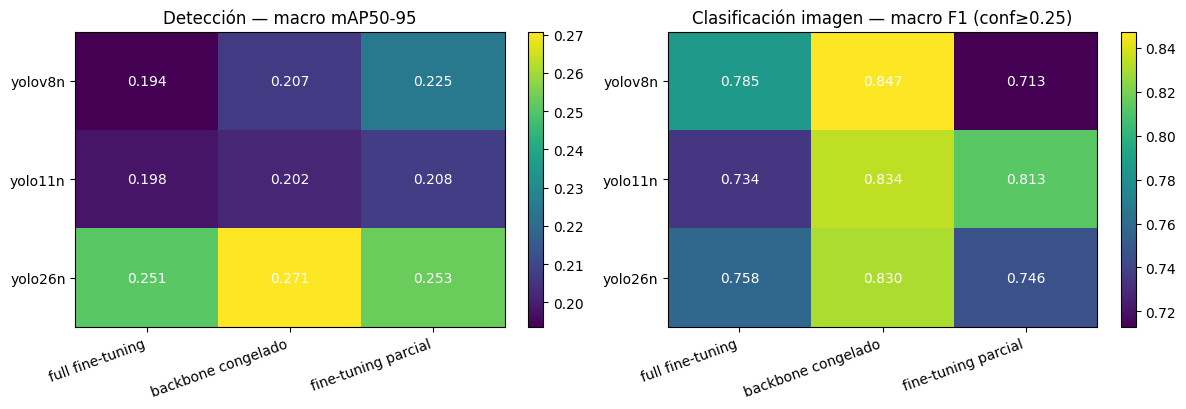

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

if not summary.empty and "macro_map50_95" in summary.columns:
    pivot_det = summary.pivot(index="architecture", columns="strategy", values="macro_map50_95")
    pivot_det = pivot_det.reindex(index=ARCHITECTURES, columns=STRATEGIES)
    im0 = axes[0].imshow(pivot_det.to_numpy(dtype=float), cmap="viridis", aspect="auto")
    axes[0].set_xticks(range(len(STRATEGIES)))
    axes[0].set_xticklabels([STRATEGY_LABEL[s] for s in STRATEGIES], rotation=20, ha="right")
    axes[0].set_yticks(range(len(ARCHITECTURES)))
    axes[0].set_yticklabels(ARCHITECTURES)
    axes[0].set_title("Detección — macro mAP50-95")
    for i, arch in enumerate(ARCHITECTURES):
        for j, strat in enumerate(STRATEGIES):
            val = pivot_det.loc[arch, strat]
            axes[0].text(j, i, "—" if pd.isna(val) else f"{val:.3f}", ha="center", va="center", color="white", fontsize=10)
    fig.colorbar(im0, ax=axes[0], fraction=0.046)
else:
    axes[0].text(0.5, 0.5, "sin summary.csv", ha="center", va="center")
    axes[0].axis("off")

if not clf_summary.empty:
    pivot_clf = clf_summary.pivot(index="architecture", columns="strategy", values="macro_img_f1")
    pivot_clf = pivot_clf.reindex(index=ARCHITECTURES, columns=STRATEGIES)
    im1 = axes[1].imshow(pivot_clf.to_numpy(dtype=float), cmap="viridis", aspect="auto")
    axes[1].set_xticks(range(len(STRATEGIES)))
    axes[1].set_xticklabels([STRATEGY_LABEL[s] for s in STRATEGIES], rotation=20, ha="right")
    axes[1].set_yticks(range(len(ARCHITECTURES)))
    axes[1].set_yticklabels(ARCHITECTURES)
    axes[1].set_title(f"Clasificación imagen — macro F1 (conf≥{IMAGE_CONF})")
    for i, arch in enumerate(ARCHITECTURES):
        for j, strat in enumerate(STRATEGIES):
            val = pivot_clf.loc[arch, strat]
            axes[1].text(j, i, "—" if pd.isna(val) else f"{val:.3f}", ha="center", va="center", color="white", fontsize=10)
    fig.colorbar(im1, ax=axes[1], fraction=0.046)
else:
    axes[1].text(0.5, 0.5, "sin predicciones", ha="center", va="center")
    axes[1].axis("off")

plt.tight_layout()
plt.show()

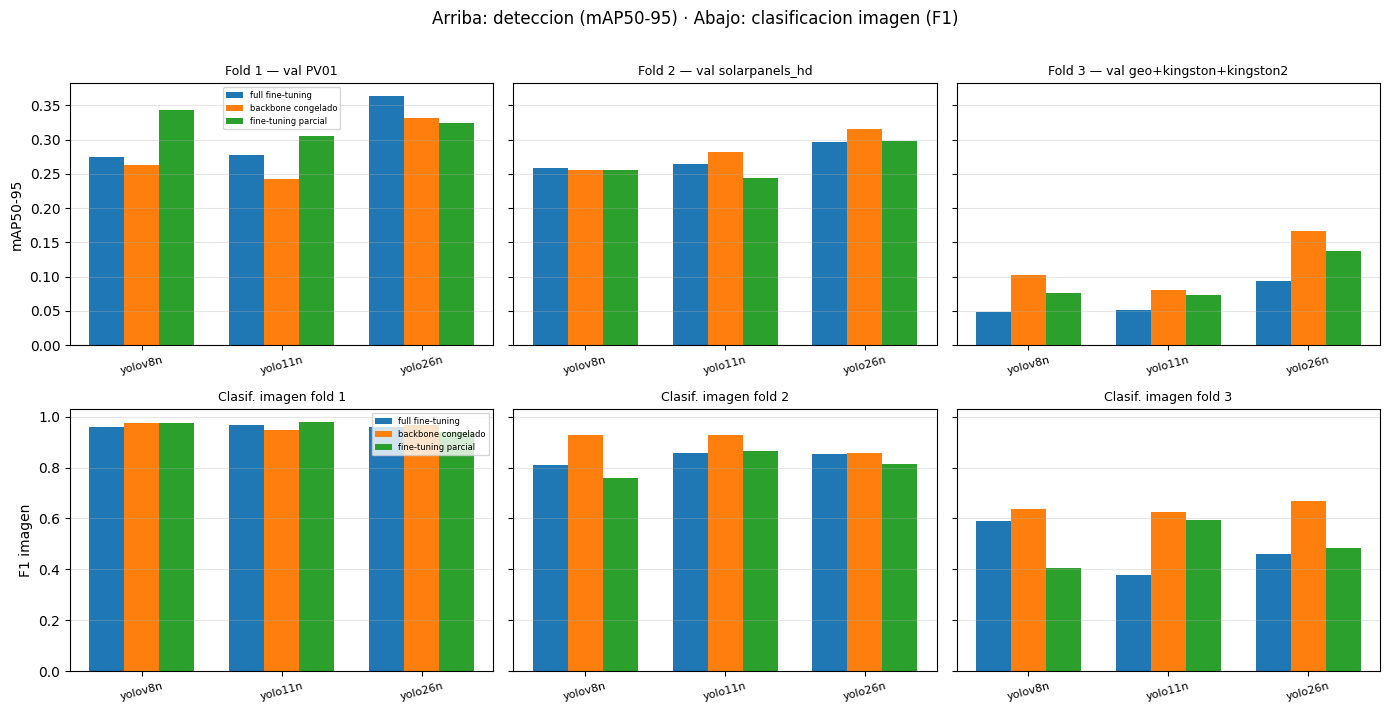

### Tabla deteccion

,experiment_id,status,architecture,strategy,fold,map50,map50_95,precision,recall,fitness,best_epoch
0,yolo11n__backbone__fold1,completed,yolo11n,backbone,1,0.4965,0.2427,0.5512,0.5096,0.2681,33
1,yolo11n__backbone__fold2,completed,yolo11n,backbone,2,0.5913,0.2825,0.6384,0.5660,0.3134,22
2,yolo11n__backbone__fold3,completed,yolo11n,backbone,3,0.1412,0.0807,0.3429,0.1772,0.0868,2
3,yolo11n__full__fold1,completed,yolo11n,full,1,0.5216,0.2777,0.5761,0.4997,0.3021,23
4,yolo11n__full__fold2,completed,yolo11n,full,2,0.4966,0.2650,0.6078,0.4525,0.2882,45
5,yolo11n__full__fold3,completed,yolo11n,full,3,0.1067,0.0511,0.2656,0.1772,0.0567,7
6,yolo11n__partial__fold1,completed,yolo11n,partial,1,0.5438,0.3051,0.6612,0.5017,0.3290,11
7,yolo11n__partial__fold2,completed,yolo11n,partial,2,0.5285,0.2439,0.6141,0.4996,0.2724,21
8,yolo11n__partial__fold3,completed,yolo11n,partial,3,0.1246,0.0738,0.3337,0.1266,0.0789,7
9,yolo26n__backbone__fold1,completed,yolo26n,backbone,1,0.6147,0.3311,0.6821,0.5489,0.3595,16


### Tabla clasificacion imagen

,experiment_id,architecture,strategy,fold,available,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
0,yolov8n__full__fold1,yolov8n,full,1,True,478,477,1,438,0,1,39,1.0000,0.9182,1.0000,0.9574,0.9184
1,yolov8n__full__fold2,yolov8n,full,2,True,316,284,32,195,3,29,89,0.9848,0.6866,0.9062,0.8091,0.7089
2,yolov8n__full__fold3,yolov8n,full,3,True,106,44,62,25,16,46,19,0.6098,0.5682,0.7419,0.5882,0.6698
3,yolov8n__backbone__fold1,yolov8n,backbone,1,True,478,477,1,455,0,1,22,1.0000,0.9539,1.0000,0.9764,0.9540
4,yolov8n__backbone__fold2,yolov8n,backbone,2,True,316,284,32,257,13,19,27,0.9519,0.9049,0.5938,0.9278,0.8734
5,yolov8n__backbone__fold3,yolov8n,backbone,3,True,106,44,62,29,18,44,15,0.6170,0.6591,0.7097,0.6374,0.6887
6,yolov8n__partial__fold1,yolov8n,partial,1,True,478,477,1,454,0,1,23,1.0000,0.9518,1.0000,0.9753,0.9519
7,yolov8n__partial__fold2,yolov8n,partial,2,True,316,284,32,175,3,29,109,0.9831,0.6162,0.9062,0.7576,0.6456
8,yolov8n__partial__fold3,yolov8n,partial,3,True,106,44,62,13,7,55,31,0.6500,0.2955,0.8871,0.4062,0.6415
9,yolo11n__full__fold1,yolo11n,full,1,True,478,477,1,447,1,0,30,0.9978,0.9371,0.0000,0.9665,0.9351


In [22]:
completed = experiments.copy() if not experiments.empty else pd.DataFrame()
if not completed.empty and "status" in completed.columns:
    done = completed[completed["status"] == "completed"]
    if not done.empty:
        completed = done

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey="row")
for j, fold in enumerate(FOLDS):
    ax = axes[0, j]
    ax.set_title(FOLD_LABEL[fold], fontsize=9)
    subset = (
        completed[completed["fold"] == fold]
        if (not completed.empty and "fold" in completed.columns)
        else completed.iloc[0:0]
    )
    if subset.empty or "map50_95" not in subset.columns:
        ax.text(0.5, 0.5, "sin datos", ha="center", va="center", transform=ax.transAxes)
    else:
        pivot = subset.pivot_table(index="architecture", columns="strategy", values="map50_95", aggfunc="first")
        pivot = pivot.reindex(index=ARCHITECTURES, columns=STRATEGIES)
        x = np.arange(len(ARCHITECTURES))
        width = 0.25
        for k, strat in enumerate(STRATEGIES):
            vals = [pivot.loc[a, strat] if a in pivot.index else np.nan for a in ARCHITECTURES]
            ax.bar(x + (k - 1) * width, vals, width, label=STRATEGY_LABEL[strat] if fold == 1 else None)
        ax.set_xticks(x)
        ax.set_xticklabels(ARCHITECTURES, rotation=15, fontsize=8)
        ax.set_ylabel("mAP50-95" if fold == 1 else "")
        ax.grid(axis="y", alpha=0.3)
        if fold == 1:
            ax.legend(fontsize=6)

    ax = axes[1, j]
    ax.set_title(f"Clasif. imagen fold {fold}", fontsize=9)
    subset = combined_clf[combined_clf["fold"] == fold] if not combined_clf.empty else combined_clf
    if subset.empty:
        ax.text(0.5, 0.5, "sin predicciones", ha="center", va="center", transform=ax.transAxes)
    else:
        pivot = subset.pivot_table(index="architecture", columns="strategy", values="f1", aggfunc="first")
        pivot = pivot.reindex(index=ARCHITECTURES, columns=STRATEGIES)
        x = np.arange(len(ARCHITECTURES))
        width = 0.25
        for k, strat in enumerate(STRATEGIES):
            vals = [pivot.loc[a, strat] if a in pivot.index else np.nan for a in ARCHITECTURES]
            ax.bar(x + (k - 1) * width, vals, width, label=STRATEGY_LABEL[strat] if fold == 1 else None)
        ax.set_xticks(x)
        ax.set_xticklabels(ARCHITECTURES, rotation=15, fontsize=8)
        ax.set_ylabel("F1 imagen" if fold == 1 else "")
        ax.grid(axis="y", alpha=0.3)
        if fold == 1:
            ax.legend(fontsize=6)

fig.suptitle("Arriba: deteccion (mAP50-95) · Abajo: clasificacion imagen (F1)", y=1.01)
plt.tight_layout()
plt.show()

if not experiments.empty:
    metric_cols = [
        c for c in ("map50", "map50_95", "precision", "recall", "fitness", "best_epoch")
        if c in experiments.columns
    ]
    display(Markdown("### Tabla deteccion"))
    display(
        experiments.sort_values(["architecture", "strategy", "fold"])[
            ["experiment_id", "status", "architecture", "strategy", "fold"] + metric_cols
        ].reset_index(drop=True)
    )

if not image_clf.empty:
    show_cols = [
        c for c in (
            "experiment_id", "architecture", "strategy", "fold", "available",
            "n_images", "n_gt_positive", "n_gt_negative",
            "tp", "fp", "tn", "fn", "precision", "recall", "specificity", "f1", "accuracy",
        )
        if c in image_clf.columns
    ]
    display(Markdown("### Tabla clasificacion imagen"))
    display(image_clf.query("scope == 'combined'")[show_cols].reset_index(drop=True))


## 5. Fold 3 — por fuente

Deteccion: `fold_metrics.csv` (AP por fuente; kingston2 solo FP de cajas).
Clasificacion imagen: TP/FP/TN/FN por fuente (en kingston2 todas son negativas).


In [23]:
if fold_metrics.empty:
    print("fold_metrics.csv vacio.")
else:
    display(Markdown("### Deteccion por fuente"))
    display(fold_metrics.sort_values(["architecture", "strategy", "fold", "scope", "source"]).reset_index(drop=True))

fold3_clf = image_clf.query("fold == 3 and available == True").copy() if not image_clf.empty else pd.DataFrame()
if fold3_clf.empty:
    print("Sin clasificacion imagen para fold 3.")
else:
    display(Markdown("### Clasificacion imagen — fold 3"))
    cols = [
        c for c in (
            "architecture", "strategy", "scope", "source",
            "n_images", "n_gt_positive", "n_gt_negative",
            "tp", "fp", "tn", "fn", "precision", "recall", "specificity", "f1", "accuracy",
        )
        if c in fold3_clf.columns
    ]
    display(fold3_clf[cols].sort_values(["architecture", "strategy", "scope", "source"]).reset_index(drop=True))
    k2 = fold3_clf[fold3_clf["source"] == "kingston2"]
    if not k2.empty:
        display(Markdown("#### kingston2 (solo negativas): FP imagen = alarmas falsas"))
        display(k2[["architecture", "strategy", "n_images", "fp", "tn", "specificity", "accuracy"]].reset_index(drop=True))


### Deteccion por fuente

,experiment_id,architecture,strategy,fold,scope,source,n_images,n_positive_images,n_negative_images,n_boxes,map50,map50_95,precision,recall,fitness,fp_images,fp_boxes,conf_threshold,note
0,yolo11n__backbone__fold1,yolo11n,backbone,1,combined,PV01,478,477,1,3556,0.4965,0.2427,0.5512,0.5096,0.2681,NaN,NaN,NaN,NaN
1,yolo11n__backbone__fold1,yolo11n,backbone,1,source,PV01,478,477,1,3556,0.4965,0.2427,0.5512,0.5096,0.2681,NaN,NaN,NaN,La fuente ocupa toda la validación del fold. E...
2,yolo11n__backbone__fold2,yolo11n,backbone,2,combined,solarpanels_hd,316,284,32,500,0.5913,0.2825,0.6384,0.5660,0.3134,NaN,NaN,NaN,NaN
3,yolo11n__backbone__fold2,yolo11n,backbone,2,source,solarpanels_hd,316,284,32,500,0.5913,0.2825,0.6384,0.5660,0.3134,NaN,NaN,NaN,La fuente ocupa toda la validación del fold. E...
4,yolo11n__backbone__fold3,yolo11n,backbone,3,combined,geo_unknown+kingston+kingston2,106,44,62,79,0.1412,0.0807,0.3429,0.1772,0.0868,NaN,NaN,NaN,El fold 3 tiene 79 cajas en total y kingston2 ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,yolov8n__partial__fold2,yolov8n,partial,2,source,solarpanels_hd,316,284,32,500,0.5407,0.2552,0.6434,0.4940,0.2838,NaN,NaN,NaN,La fuente ocupa toda la validación del fold. E...
68,yolov8n__partial__fold3,yolov8n,partial,3,combined,geo_unknown+kingston+kingston2,106,44,62,79,0.1182,0.0765,0.2812,0.1266,0.0806,NaN,NaN,NaN,El fold 3 tiene 79 cajas en total y kingston2 ...
69,yolov8n__partial__fold3,yolov8n,partial,3,source,geo_unknown,44,10,34,13,0.2610,0.1464,0.7071,0.2308,0.1464,NaN,NaN,NaN,NaN
70,yolov8n__partial__fold3,yolov8n,partial,3,source,kingston,34,34,0,66,0.1271,0.0754,0.3305,0.1364,0.0754,NaN,NaN,NaN,NaN


### Clasificacion imagen — fold 3

,architecture,strategy,scope,source,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
0,yolo11n,backbone,combined,all,106,44,62,41,46,16,3,0.4713,0.9318,0.2581,0.6260,0.5377
1,yolo11n,backbone,source,geo_unknown,44,10,34,9,27,7,1,0.2500,0.9000,0.2059,0.3913,0.3636
2,yolo11n,backbone,source,kingston,34,34,0,32,0,0,2,1.0000,0.9412,NaN,0.9697,0.9412
3,yolo11n,backbone,source,kingston2,28,0,28,0,19,9,0,0.0000,0.0000,0.3214,0.0000,0.3214
4,yolo11n,full,combined,all,106,44,62,13,12,50,31,0.5200,0.2955,0.8065,0.3768,0.5943
5,yolo11n,full,source,geo_unknown,44,10,34,6,10,24,4,0.3750,0.6000,0.7059,0.4615,0.6818
6,yolo11n,full,source,kingston,34,34,0,7,0,0,27,1.0000,0.2059,NaN,0.3415,0.2059
7,yolo11n,full,source,kingston2,28,0,28,0,2,26,0,0.0000,0.0000,0.9286,0.0000,0.9286
8,yolo11n,partial,combined,all,106,44,62,25,15,47,19,0.6250,0.5682,0.7581,0.5952,0.6792
9,yolo11n,partial,source,geo_unknown,44,10,34,5,15,19,5,0.2500,0.5000,0.5588,0.3333,0.5455


#### kingston2 (solo negativas): FP imagen = alarmas falsas

,architecture,strategy,n_images,fp,tn,specificity,accuracy
0,yolov8n,full,28,3,25,0.8929,0.8929
1,yolov8n,backbone,28,9,19,0.6786,0.6786
2,yolov8n,partial,28,1,27,0.9643,0.9643
3,yolo11n,full,28,2,26,0.9286,0.9286
4,yolo11n,backbone,28,19,9,0.3214,0.3214
5,yolo11n,partial,28,0,28,1.0000,1.0000
6,yolo26n,full,28,0,28,1.0000,1.0000
7,yolo26n,backbone,28,6,22,0.7857,0.7857
8,yolo26n,partial,28,0,28,1.0000,1.0000


## 6. Detalle del mejor modelo: yolo26n backbone

Por defecto solo se abren los 3 folds de `yolo26n` / `backbone`.
Cambiá los filtros si querés otro experimento.


In [24]:
# Foco por defecto: mejor modelo
SELECTED_ARCHITECTURES = ["yolo26n"]
SELECTED_STRATEGIES = ["backbone"]
SELECTED_FOLDS = FOLDS  # 1, 2, 3

# Plots Ultralytics: solo los esenciales (sin results.png ni curvas P/R sueltas)
SHOW_ULTRALYTICS_PLOTS = True
PLOT_CANDIDATES = [
    ("confusion_matrix_normalized.png", "Matriz de confusión normalizada (detección)"),
    ("BoxPR_curve.png", "Curva Precision-Recall (cajas)"),
    ("BoxF1_curve.png", "Curva F1 (cajas)"),
]

print("Detalle:")
for arch in SELECTED_ARCHITECTURES:
    for strat in SELECTED_STRATEGIES:
        for fold in SELECTED_FOLDS:
            print(" -", experiment_id(arch, strat, fold))


Detalle:
 - yolo26n__backbone__fold1
 - yolo26n__backbone__fold2
 - yolo26n__backbone__fold3


---
## yolo26n__backbone__fold1
Fold 1 — val PV01 · backbone congelado

#### Deteccion (cajas)

,status,map50,map50_95,precision,recall,fitness,best_epoch,epochs_ran,train_time_sec,frozen_indices,warning,error
9,completed,0.6147,0.3311,0.6821,0.5489,0.3595,16,31,245.8000,"0,1,2,3,4,5,6,7,8,9,10",NaN,NaN


#### Clasificacion imagen (conf >= 0.25)

,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
42,478,477,1,447,0,1,30,1.0000,0.9371,1.0000,0.9675,0.9372


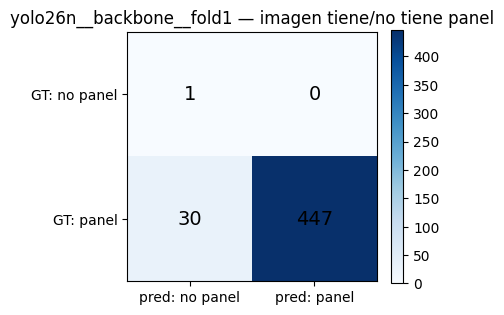

#### fold_metrics (deteccion / FP kingston2)

,experiment_id,architecture,strategy,fold,scope,source,n_images,n_positive_images,n_negative_images,n_boxes,map50,map50_95,precision,recall,fitness,fp_images,fp_boxes,conf_threshold,note
0,yolo26n__backbone__fold1,yolo26n,backbone,1,combined,PV01,478,477,1,3556,0.6147,0.3311,0.6821,0.5489,0.3595,NaN,NaN,NaN,NaN
1,yolo26n__backbone__fold1,yolo26n,backbone,1,source,PV01,478,477,1,3556,0.6147,0.3311,0.6821,0.5489,0.3595,NaN,NaN,NaN,La fuente ocupa toda la validación del fold. E...


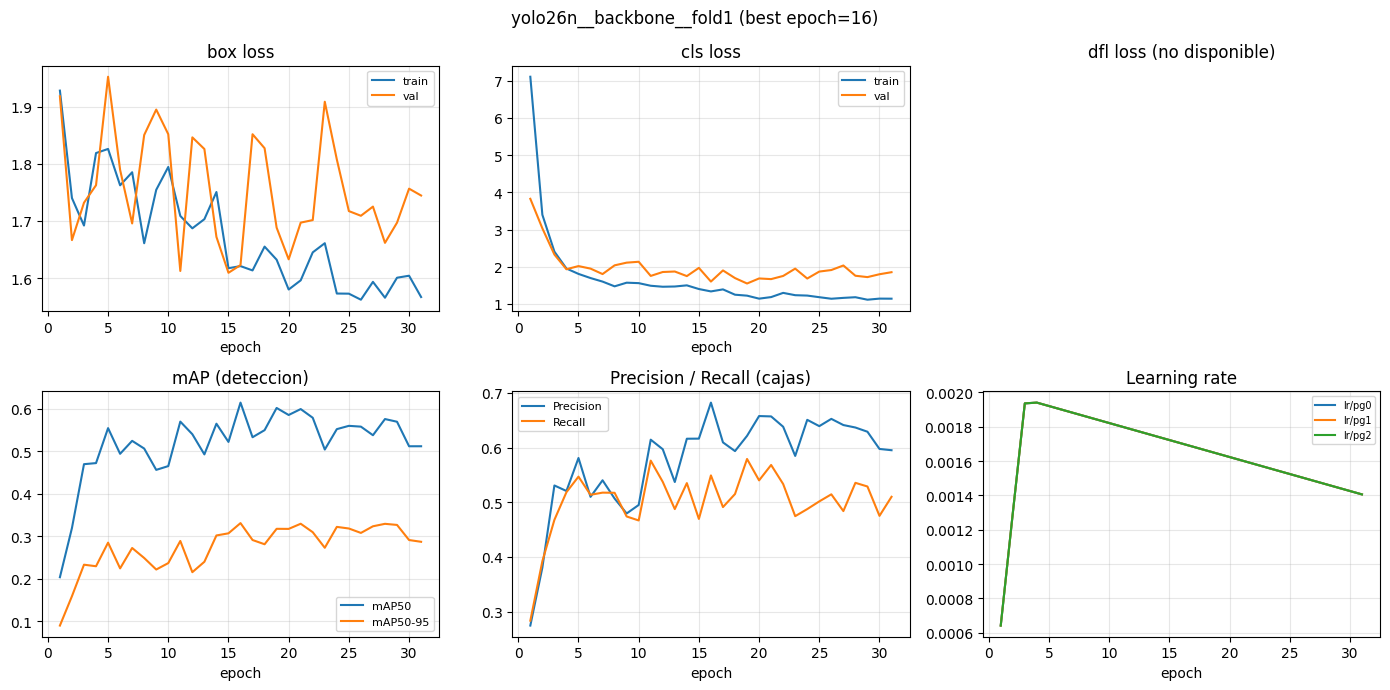

**Matriz de confusión normalizada (detección)** — `confusion_matrix_normalized.png`

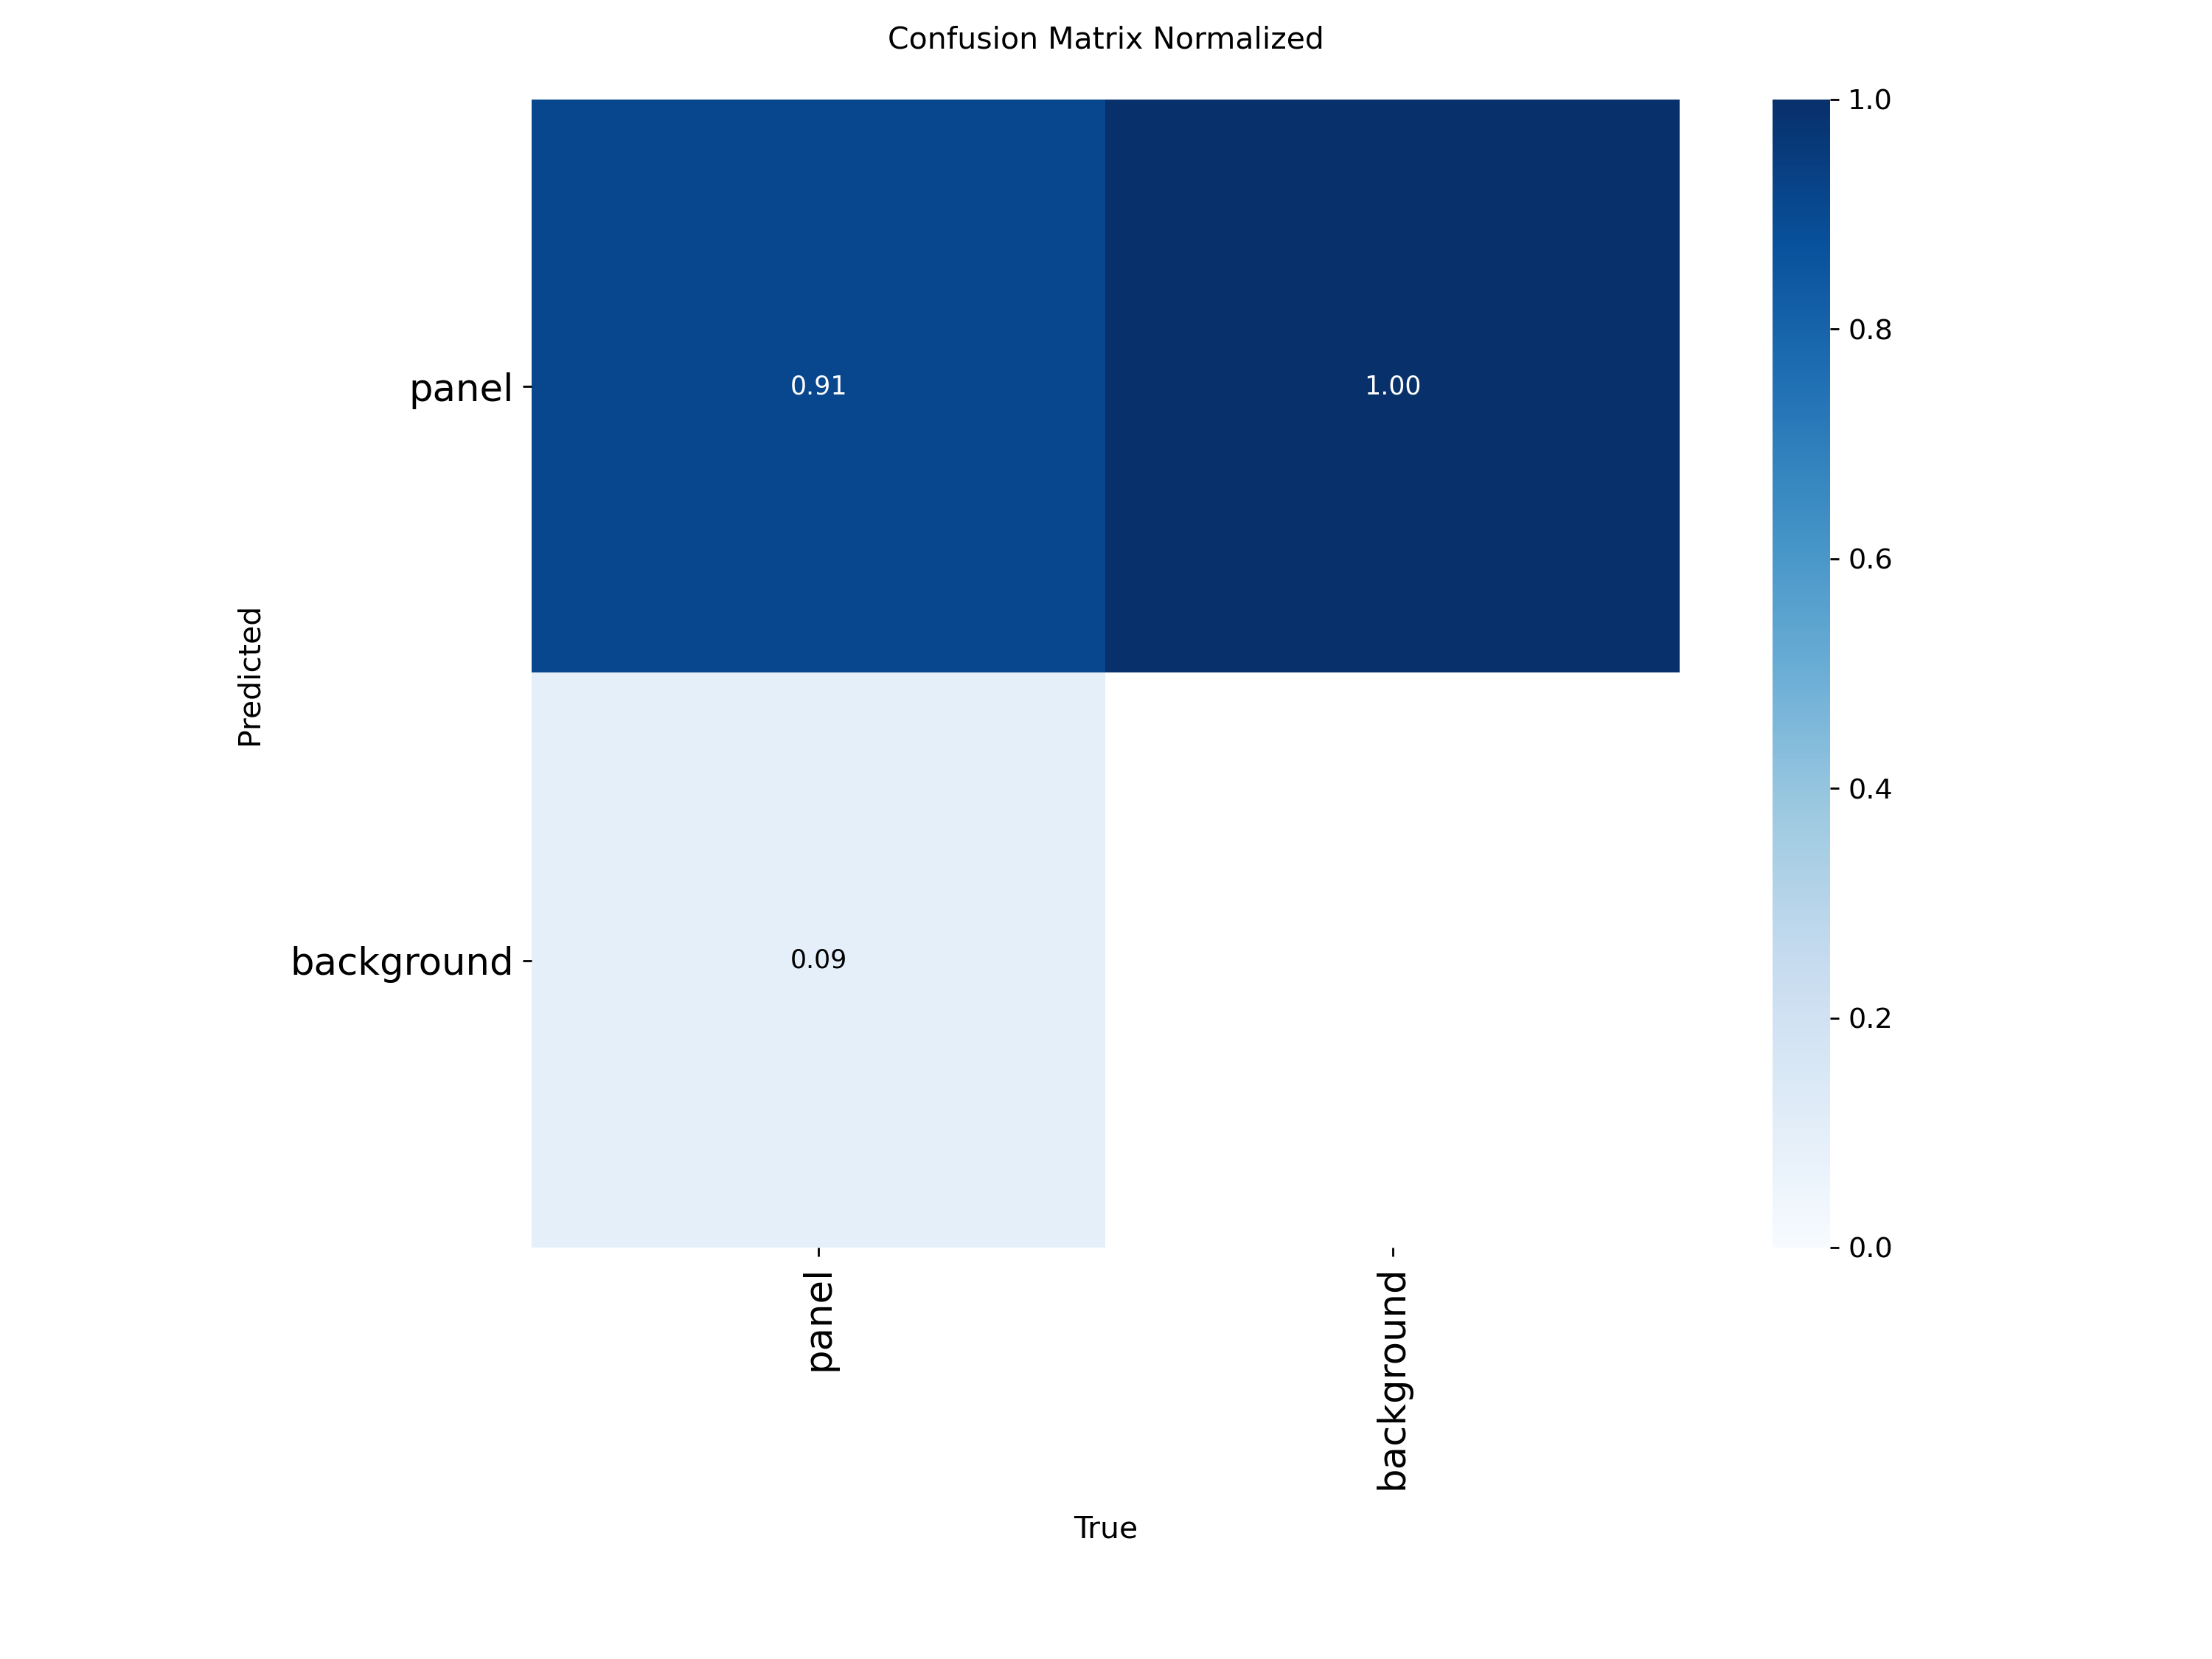

**Curva Precision-Recall (cajas)** — `BoxPR_curve.png`

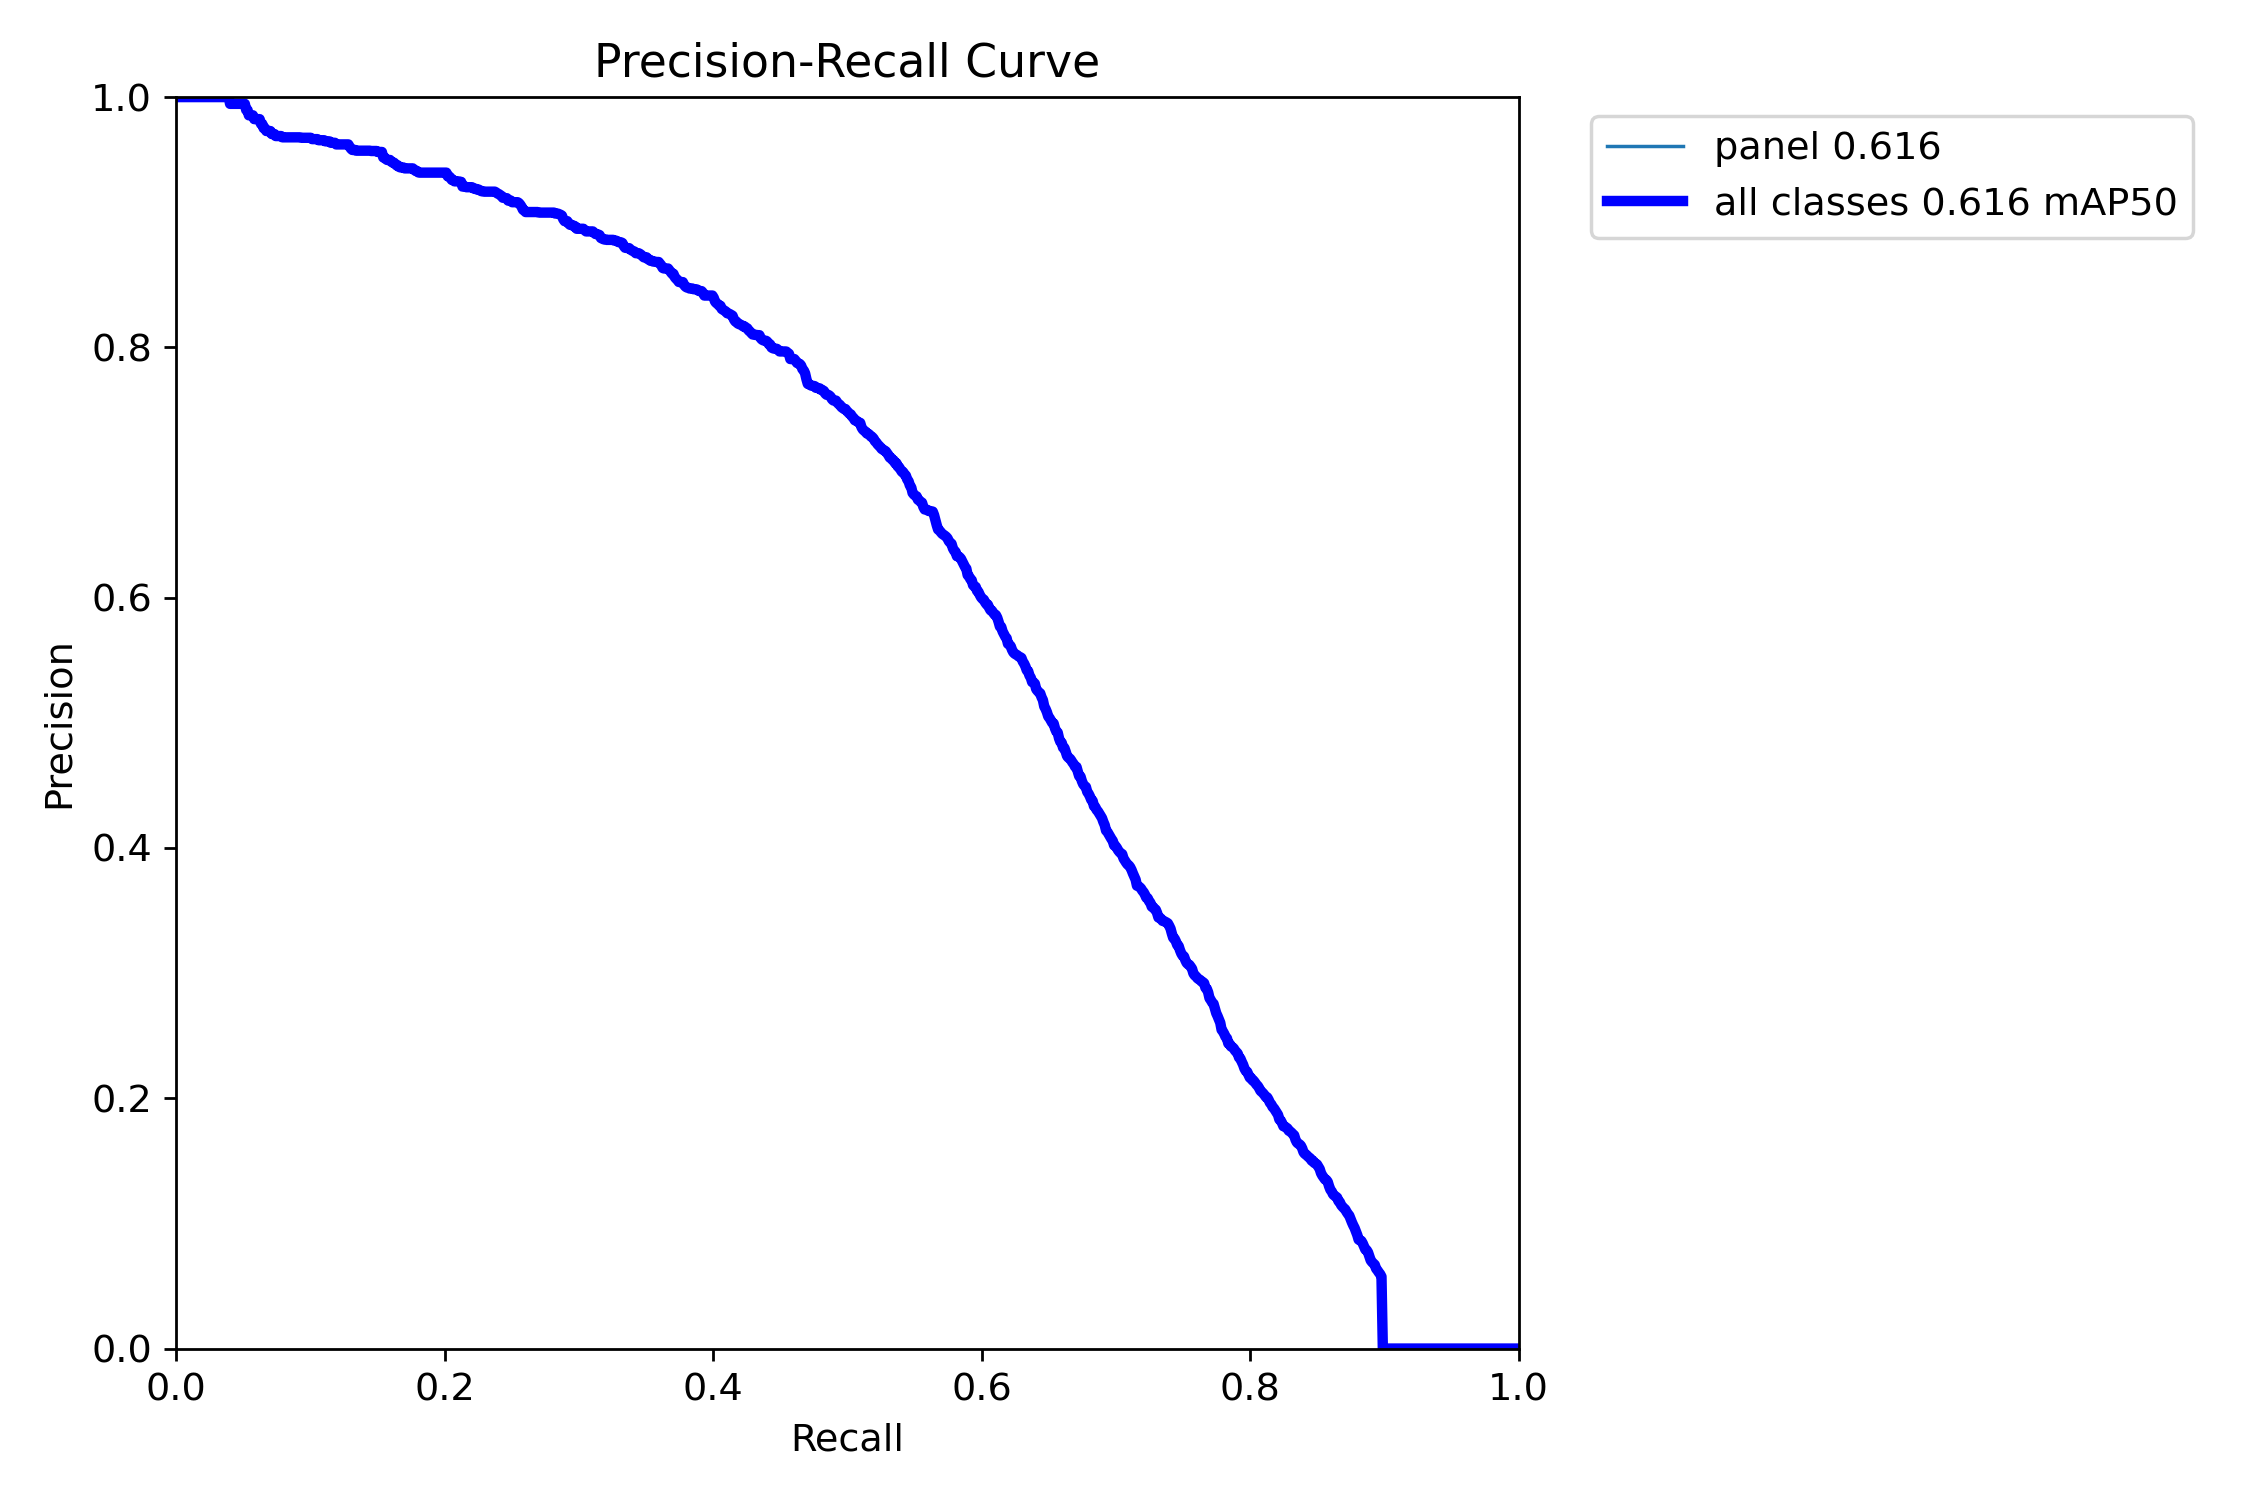

**Curva F1 (cajas)** — `BoxF1_curve.png`

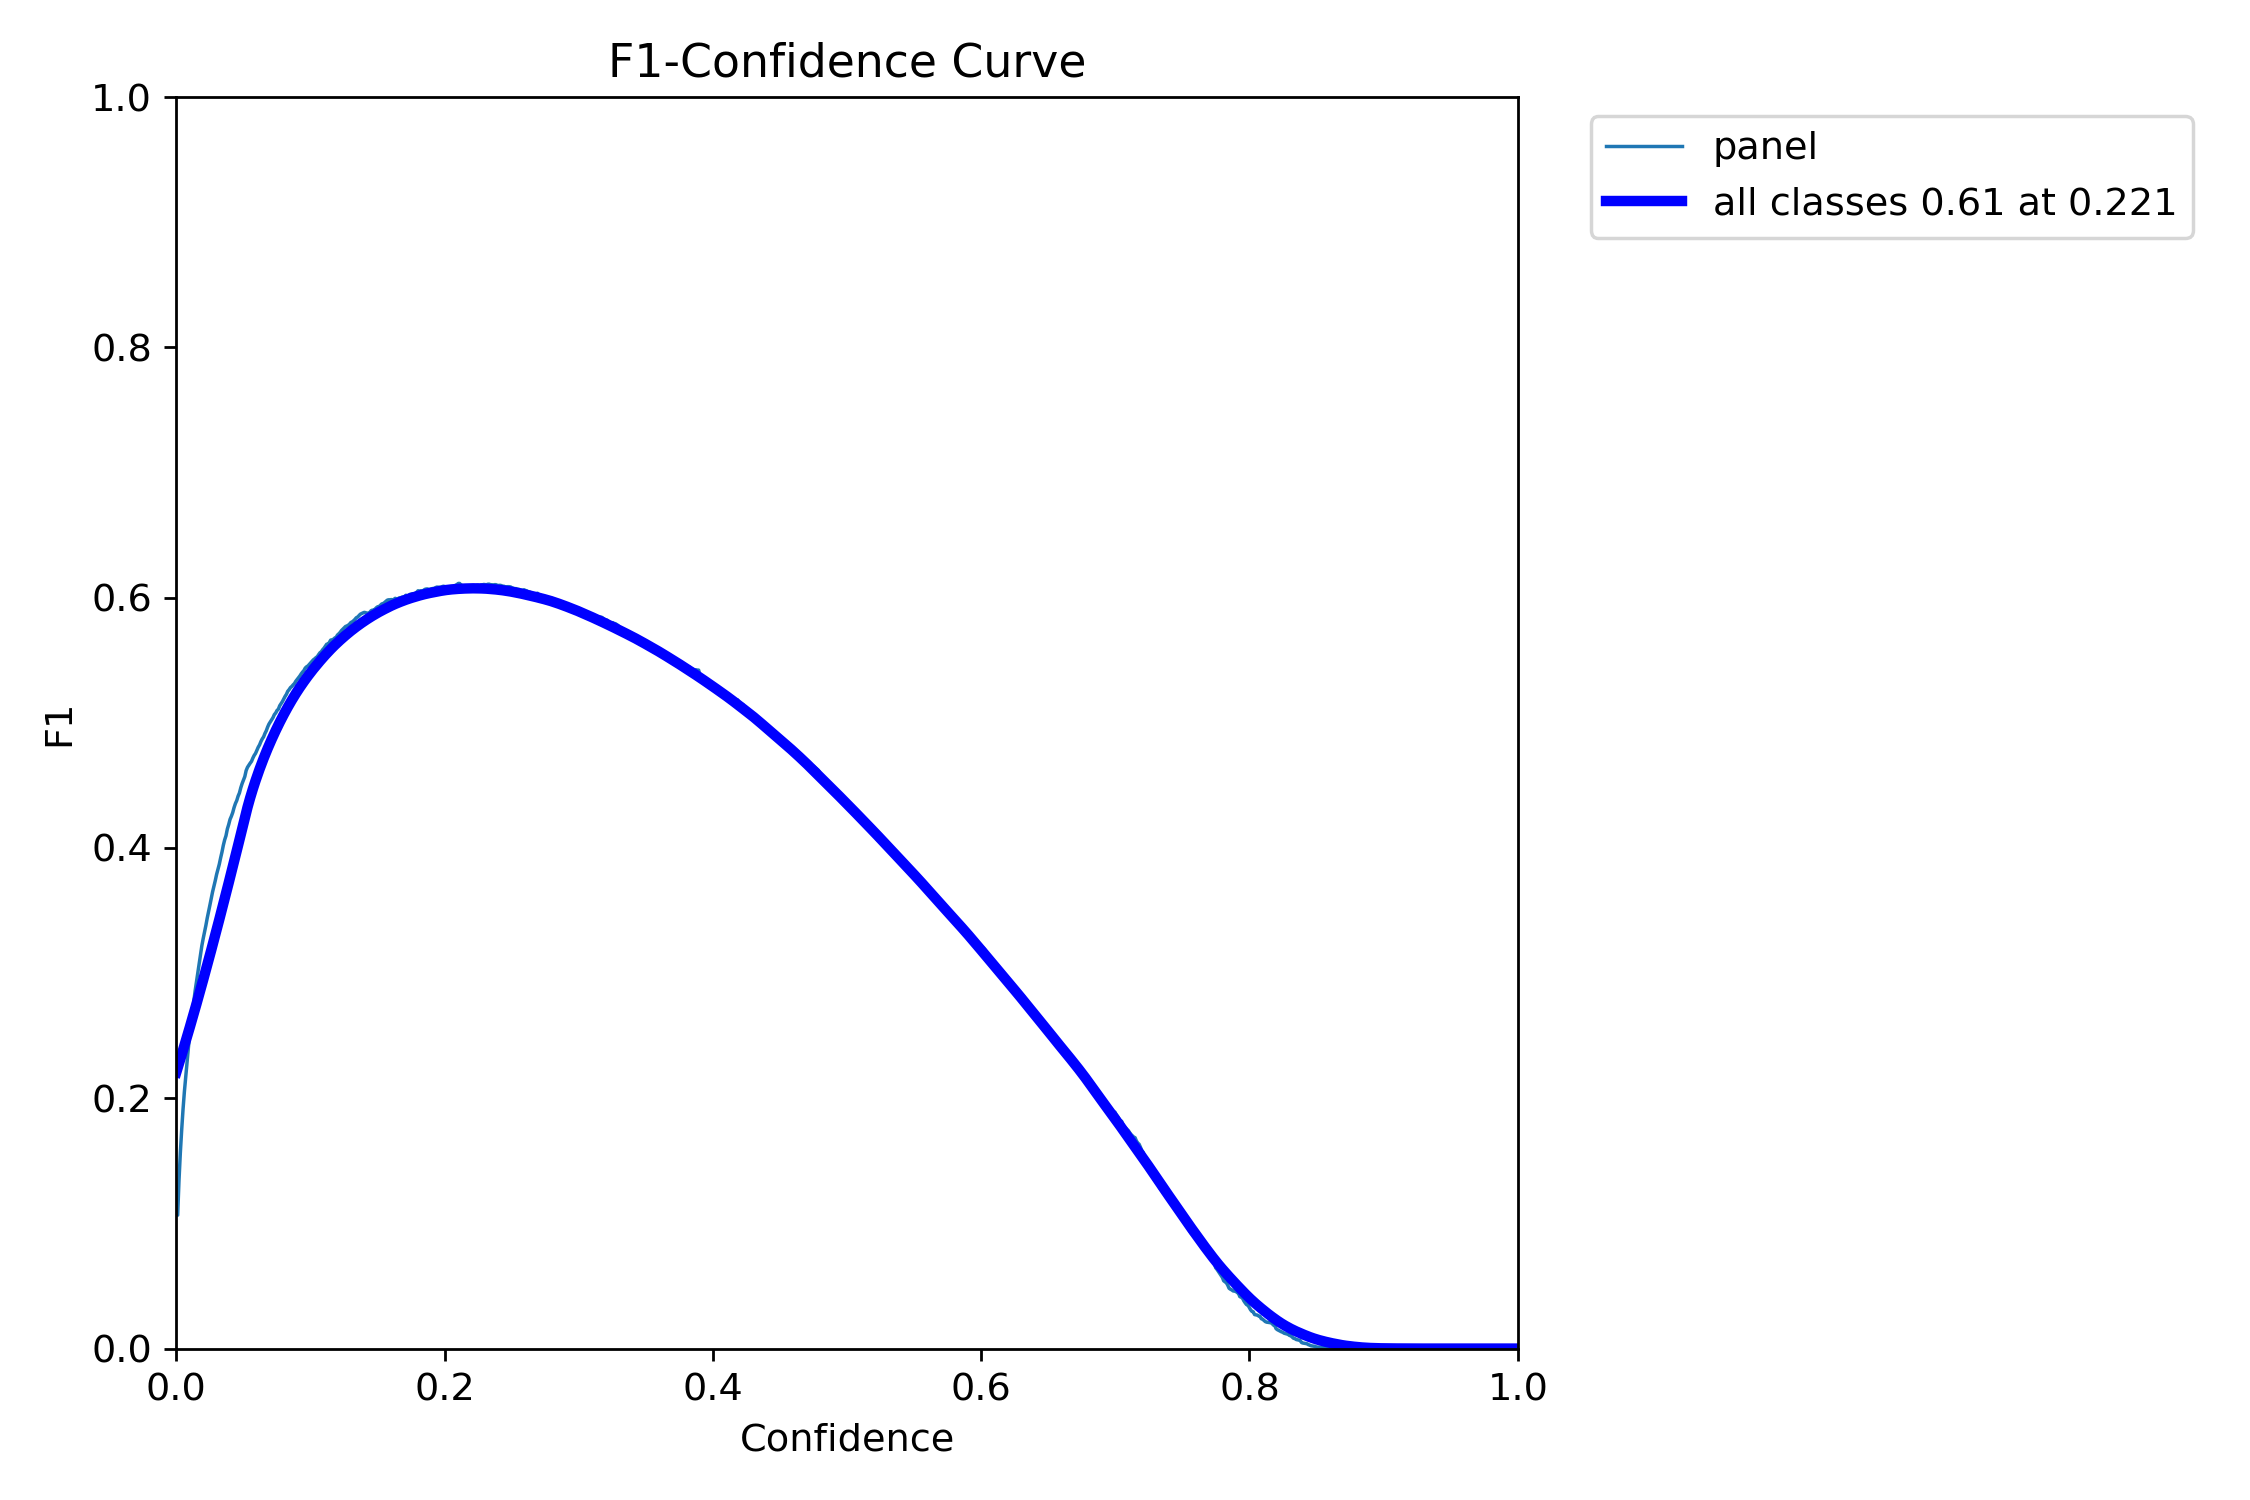

---
## yolo26n__backbone__fold2
Fold 2 — val solarpanels_hd · backbone congelado

#### Deteccion (cajas)

,status,map50,map50_95,precision,recall,fitness,best_epoch,epochs_ran,train_time_sec,frozen_indices,warning,error
10,completed,0.6145,0.3151,0.6600,0.5706,0.3451,41,56,463.1470,"0,1,2,3,4,5,6,7,8,9,10",NaN,NaN


#### Clasificacion imagen (conf >= 0.25)

,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
43,316,284,32,216,4,28,68,0.9818,0.7606,0.8750,0.8571,0.7722


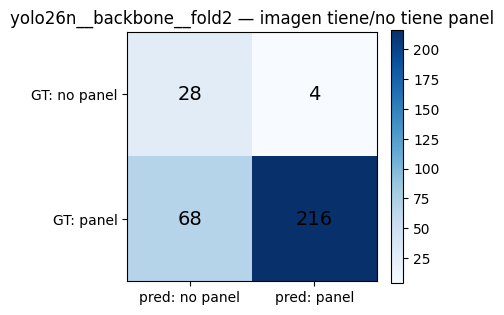

#### fold_metrics (deteccion / FP kingston2)

,experiment_id,architecture,strategy,fold,scope,source,n_images,n_positive_images,n_negative_images,n_boxes,map50,map50_95,precision,recall,fitness,fp_images,fp_boxes,conf_threshold,note
0,yolo26n__backbone__fold2,yolo26n,backbone,2,combined,solarpanels_hd,316,284,32,500,0.6145,0.3151,0.6600,0.5706,0.3451,NaN,NaN,NaN,NaN
1,yolo26n__backbone__fold2,yolo26n,backbone,2,source,solarpanels_hd,316,284,32,500,0.6145,0.3151,0.6600,0.5706,0.3451,NaN,NaN,NaN,La fuente ocupa toda la validación del fold. E...


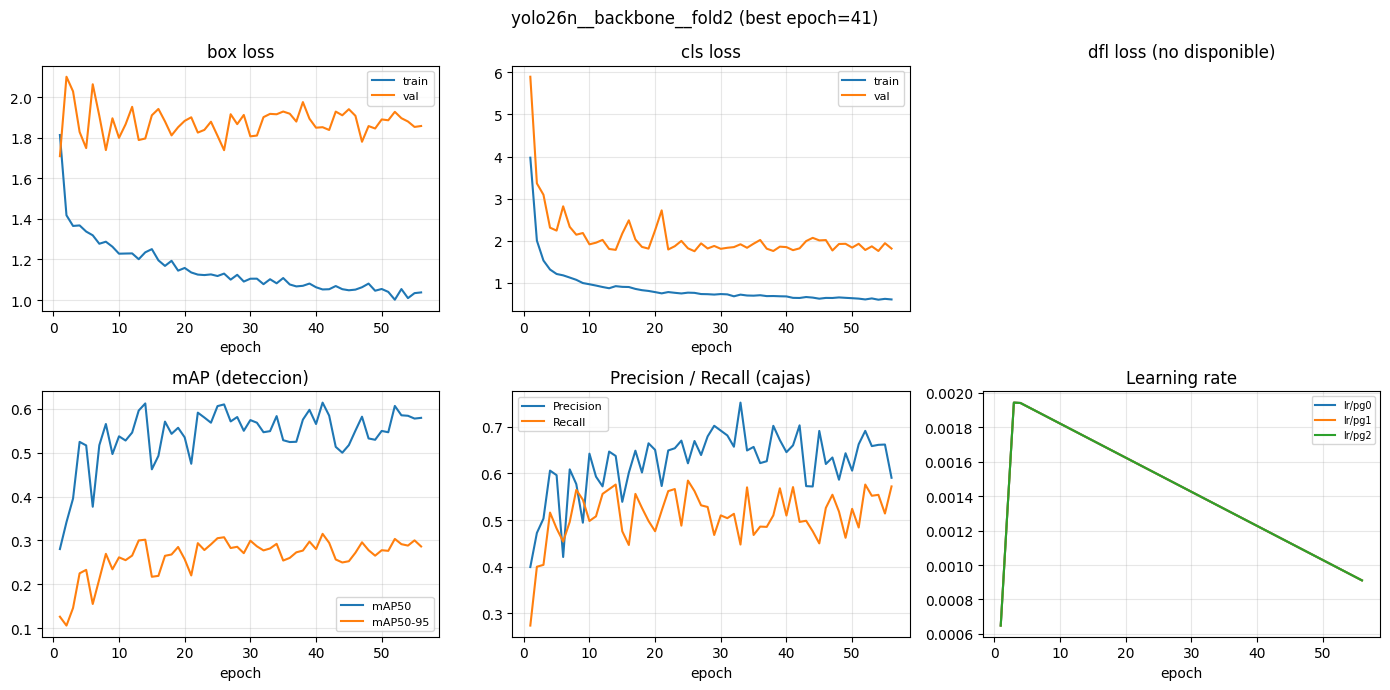

**Matriz de confusión normalizada (detección)** — `confusion_matrix_normalized.png`

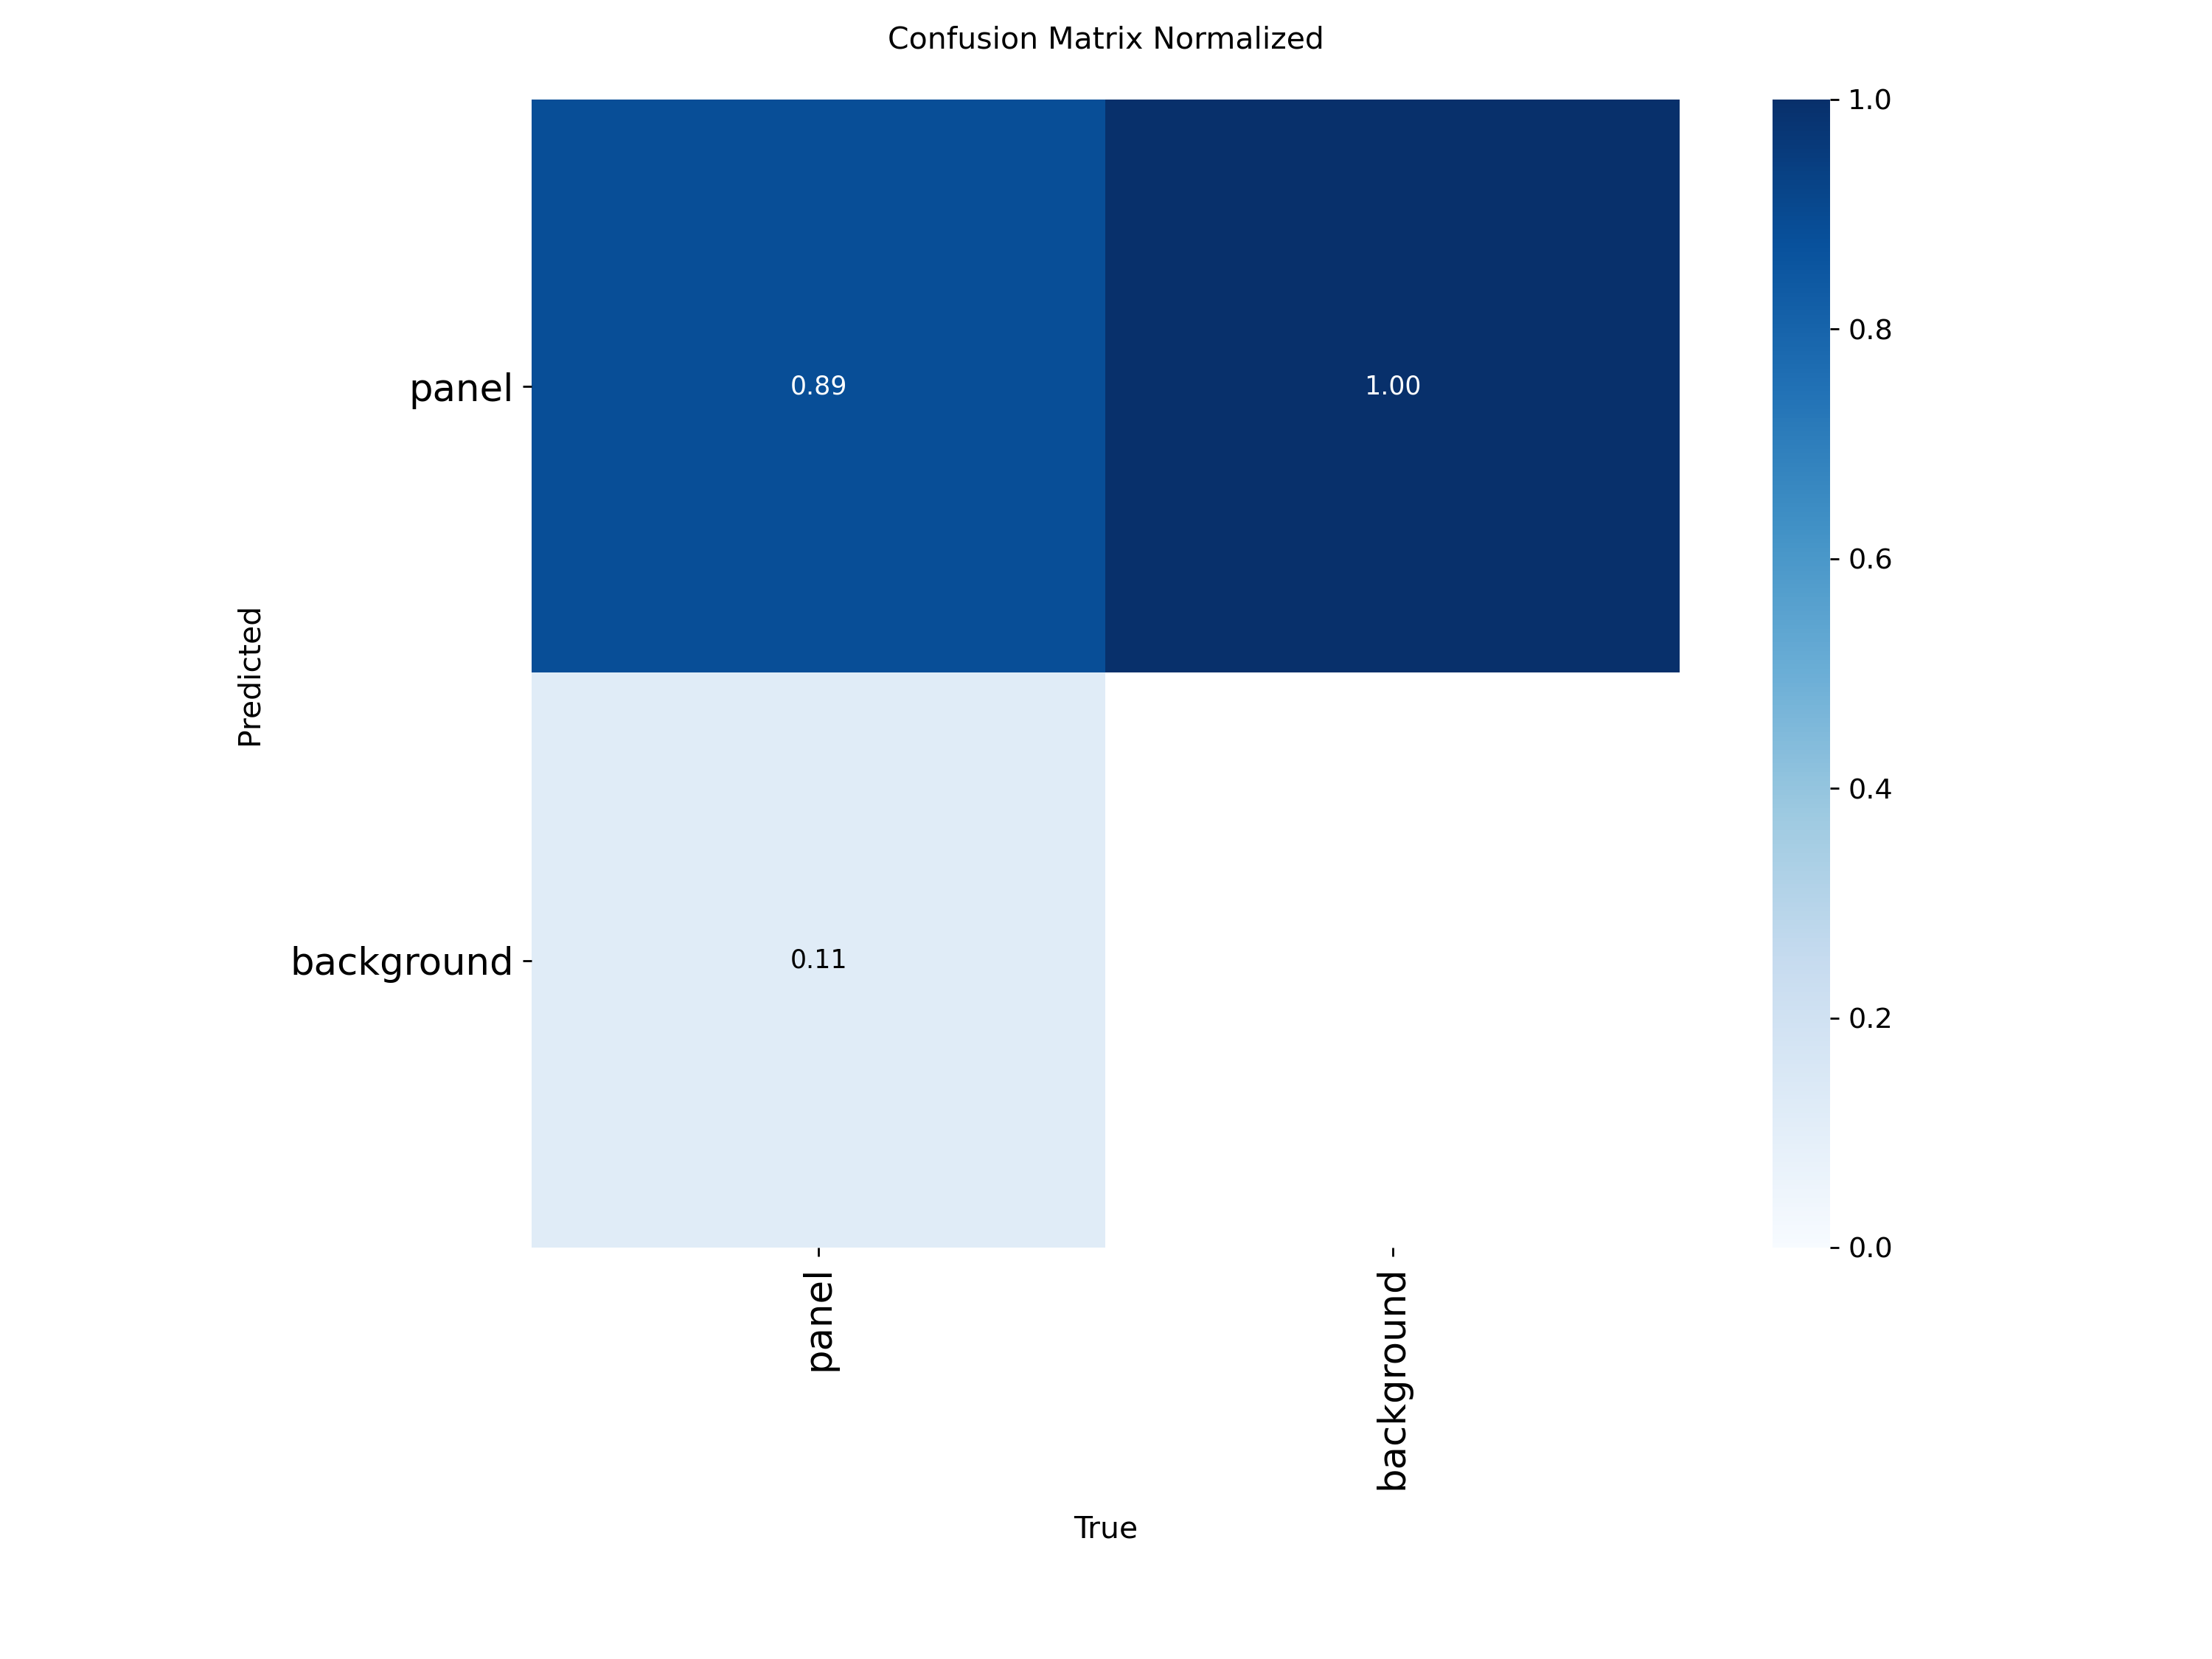

**Curva Precision-Recall (cajas)** — `BoxPR_curve.png`

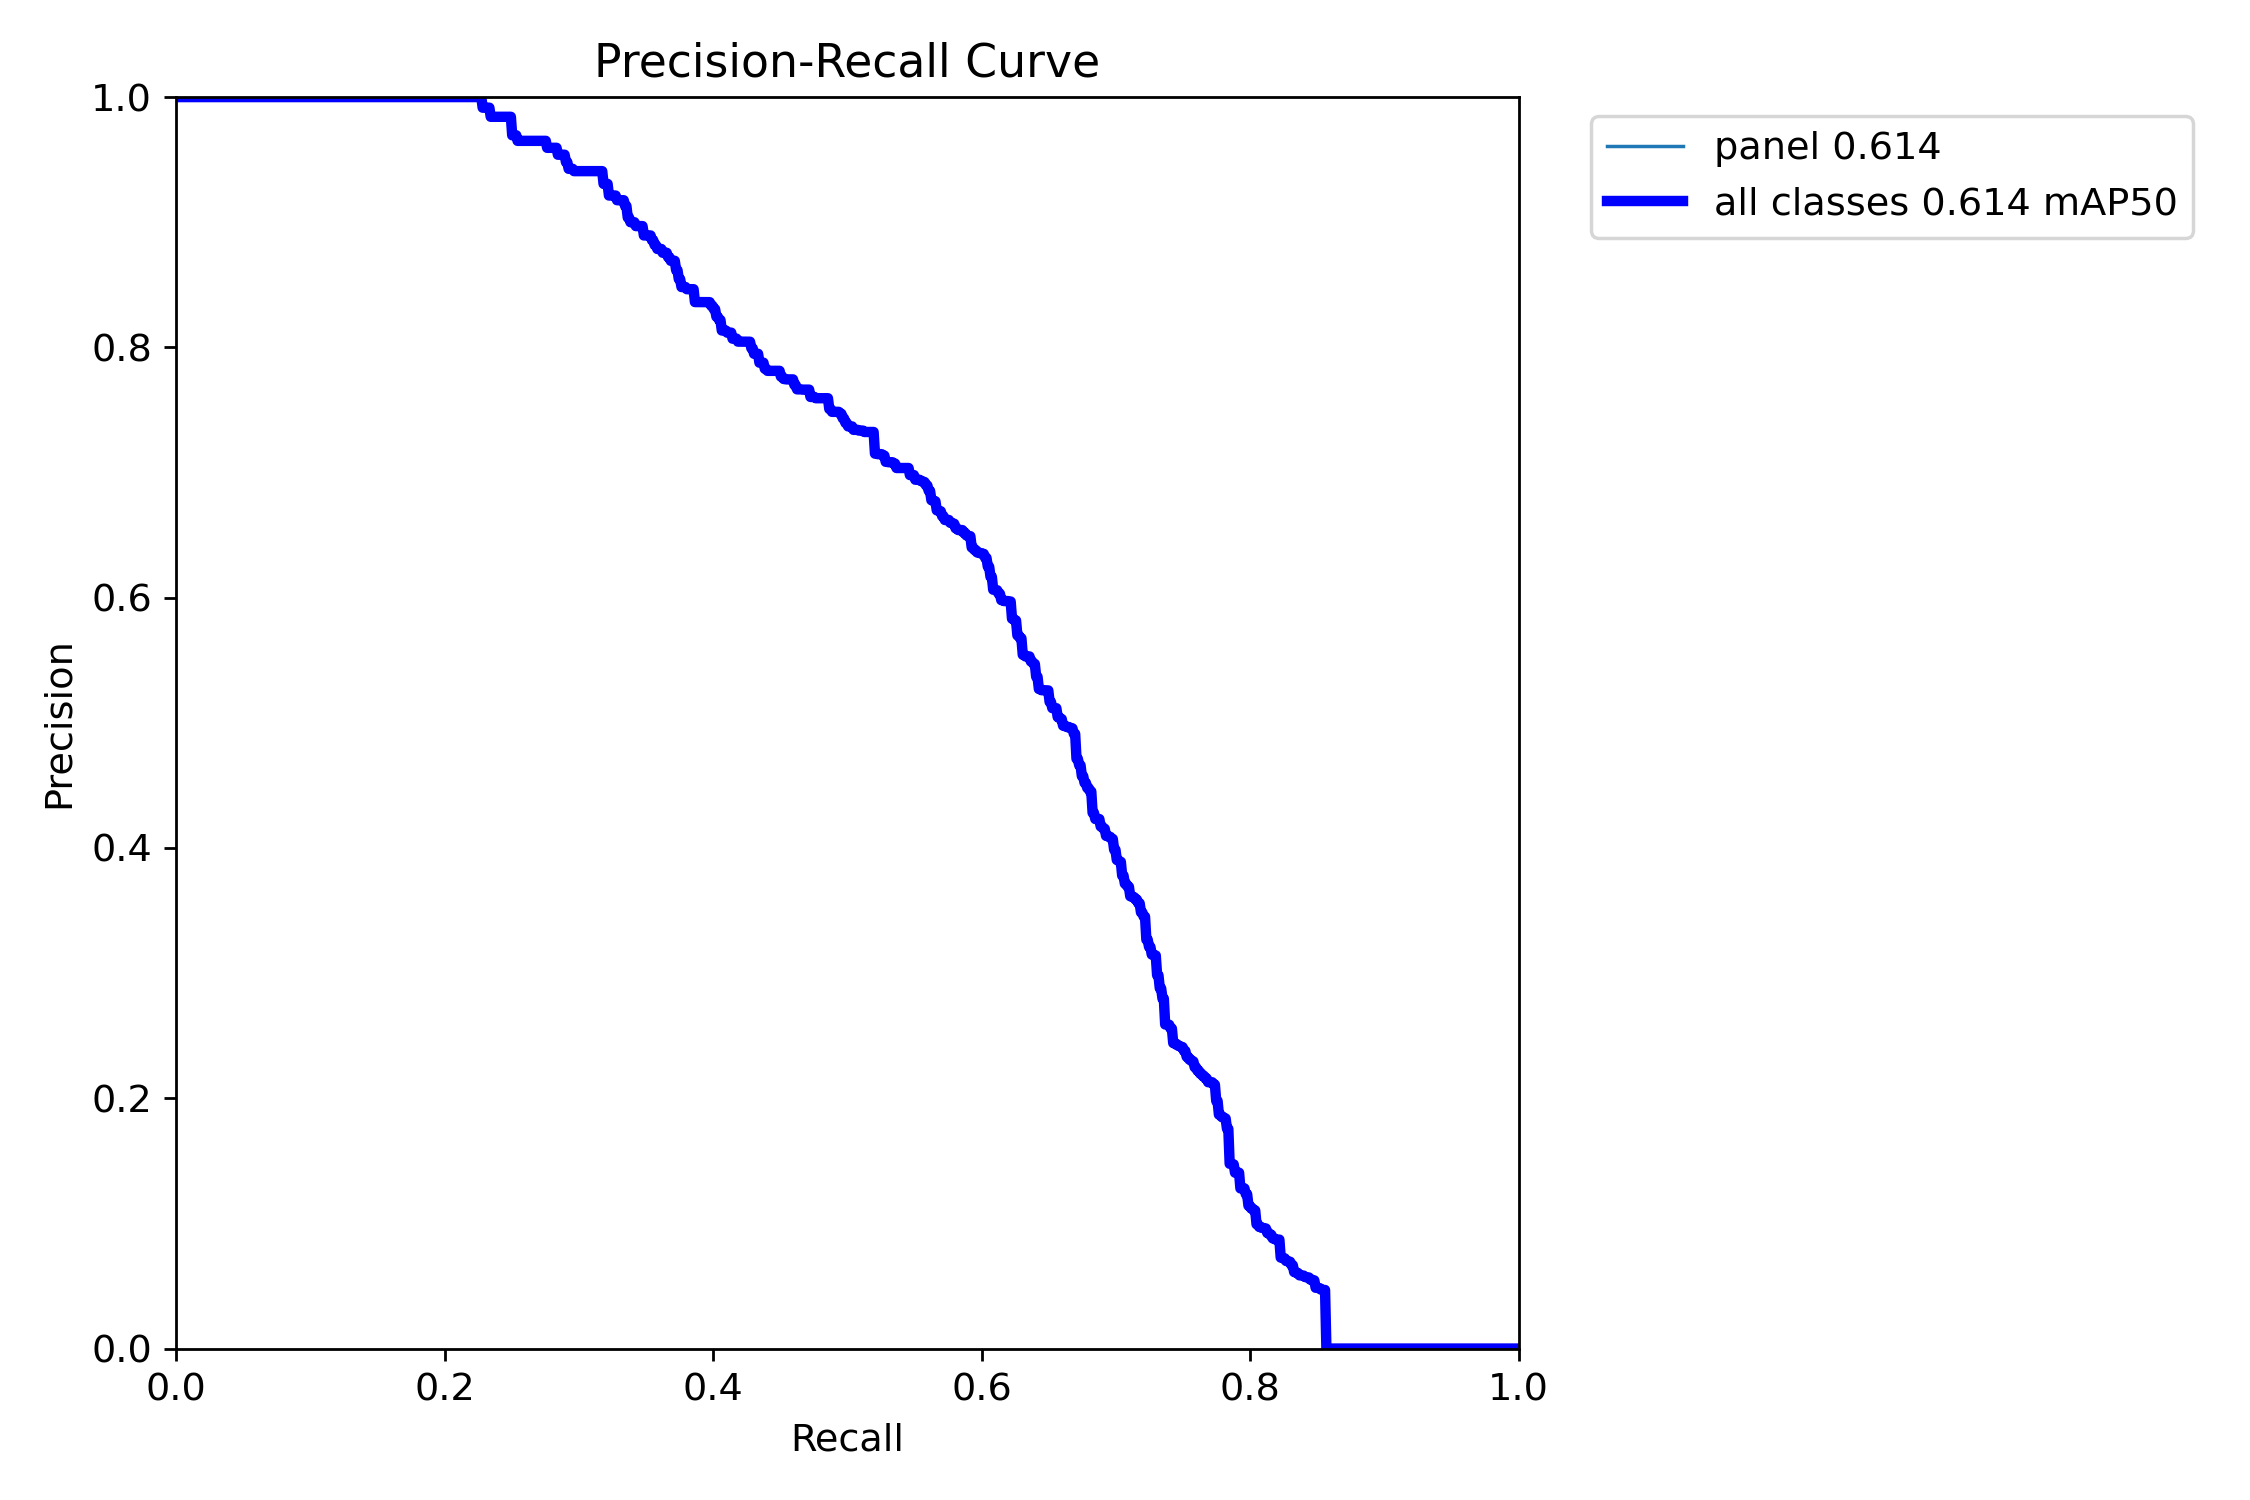

**Curva F1 (cajas)** — `BoxF1_curve.png`

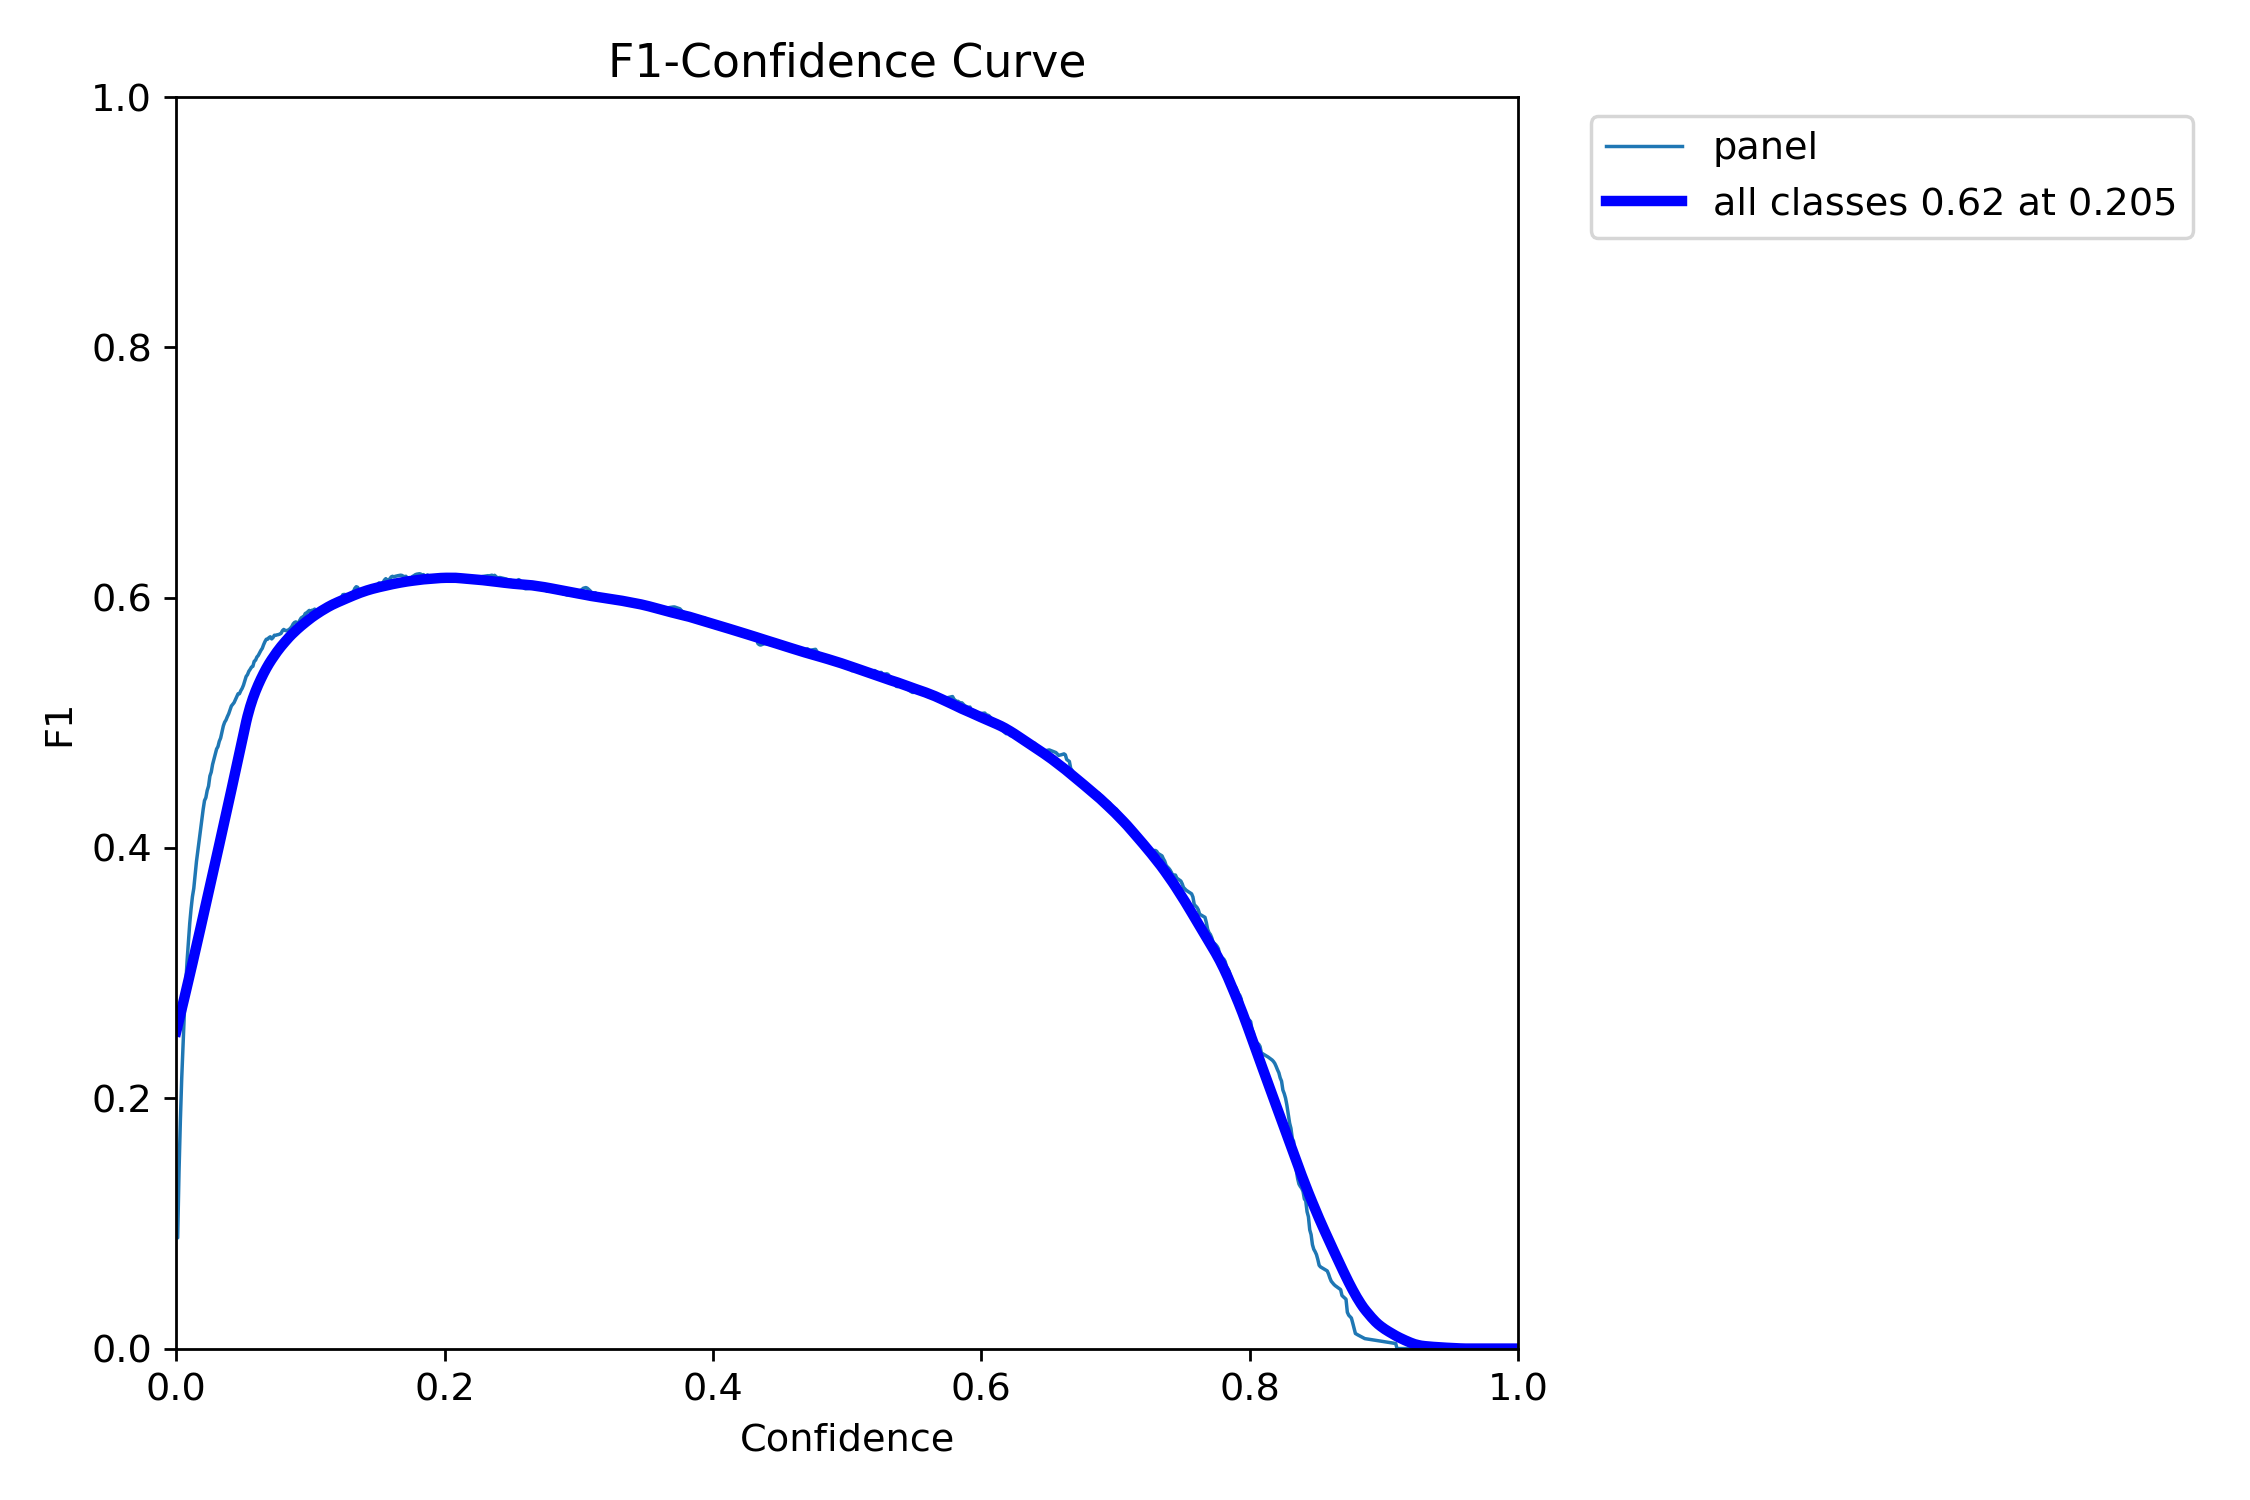

---
## yolo26n__backbone__fold3
Fold 3 — val geo+kingston+kingston2 · backbone congelado

#### Deteccion (cajas)

,status,map50,map50_95,precision,recall,fitness,best_epoch,epochs_ran,train_time_sec,frozen_indices,warning,error
11,completed,0.3004,0.1660,0.3333,0.3924,0.1794,3,18,163.9130,"0,1,2,3,4,5,6,7,8,9,10",NaN,NaN


#### Clasificacion imagen (conf >= 0.25)

,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
44,106,44,62,34,24,38,10,0.5862,0.7727,0.6129,0.6667,0.6792


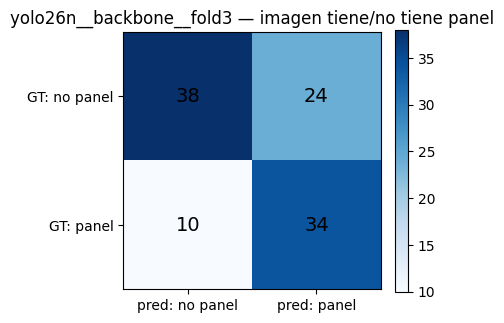

##### Por fuente (fold 3)

,experiment_id,architecture,strategy,fold,scope,source,available,conf_threshold,n_images,n_gt_positive,n_gt_negative,tp,fp,tn,fn,precision,recall,specificity,f1,accuracy
0,yolo26n__backbone__fold3,yolo26n,backbone,3,source,geo_unknown,True,0.2500,44,10,34,8,18,16,2,0.3077,0.8000,0.4706,0.4444,0.5455
1,yolo26n__backbone__fold3,yolo26n,backbone,3,source,kingston,True,0.2500,34,34,0,26,0,0,8,1.0000,0.7647,NaN,0.8667,0.7647
2,yolo26n__backbone__fold3,yolo26n,backbone,3,source,kingston2,True,0.2500,28,0,28,0,6,22,0,0.0000,0.0000,0.7857,0.0000,0.7857


#### fold_metrics (deteccion / FP kingston2)

,experiment_id,architecture,strategy,fold,scope,source,n_images,n_positive_images,n_negative_images,n_boxes,map50,map50_95,precision,recall,fitness,fp_images,fp_boxes,conf_threshold,note
0,yolo26n__backbone__fold3,yolo26n,backbone,3,combined,geo_unknown+kingston+kingston2,106,44,62,79,0.3004,0.1660,0.3333,0.3924,0.1794,NaN,NaN,NaN,El fold 3 tiene 79 cajas en total y kingston2 ...
1,yolo26n__backbone__fold3,yolo26n,backbone,3,source,geo_unknown,44,10,34,13,0.4034,0.2510,0.4735,0.3479,0.2510,NaN,NaN,NaN,NaN
2,yolo26n__backbone__fold3,yolo26n,backbone,3,source,kingston,34,34,0,66,0.3530,0.1799,0.4427,0.4545,0.1799,NaN,NaN,NaN,NaN
3,yolo26n__backbone__fold3,yolo26n,backbone,3,source,kingston2,28,0,28,0,NaN,NaN,NaN,NaN,NaN,6.0000,10.0000,0.2500,Sin objetos positivos. No se calculó AP ni rec...


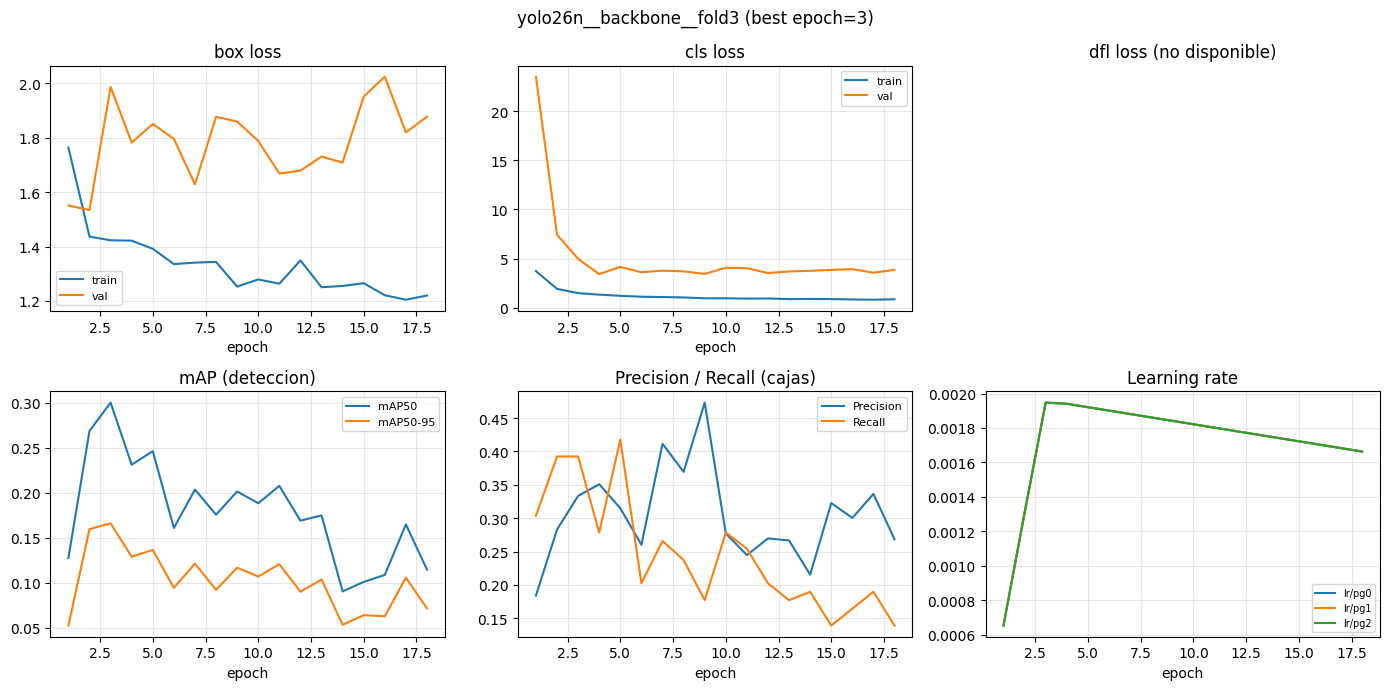

**Matriz de confusión normalizada (detección)** — `confusion_matrix_normalized.png`

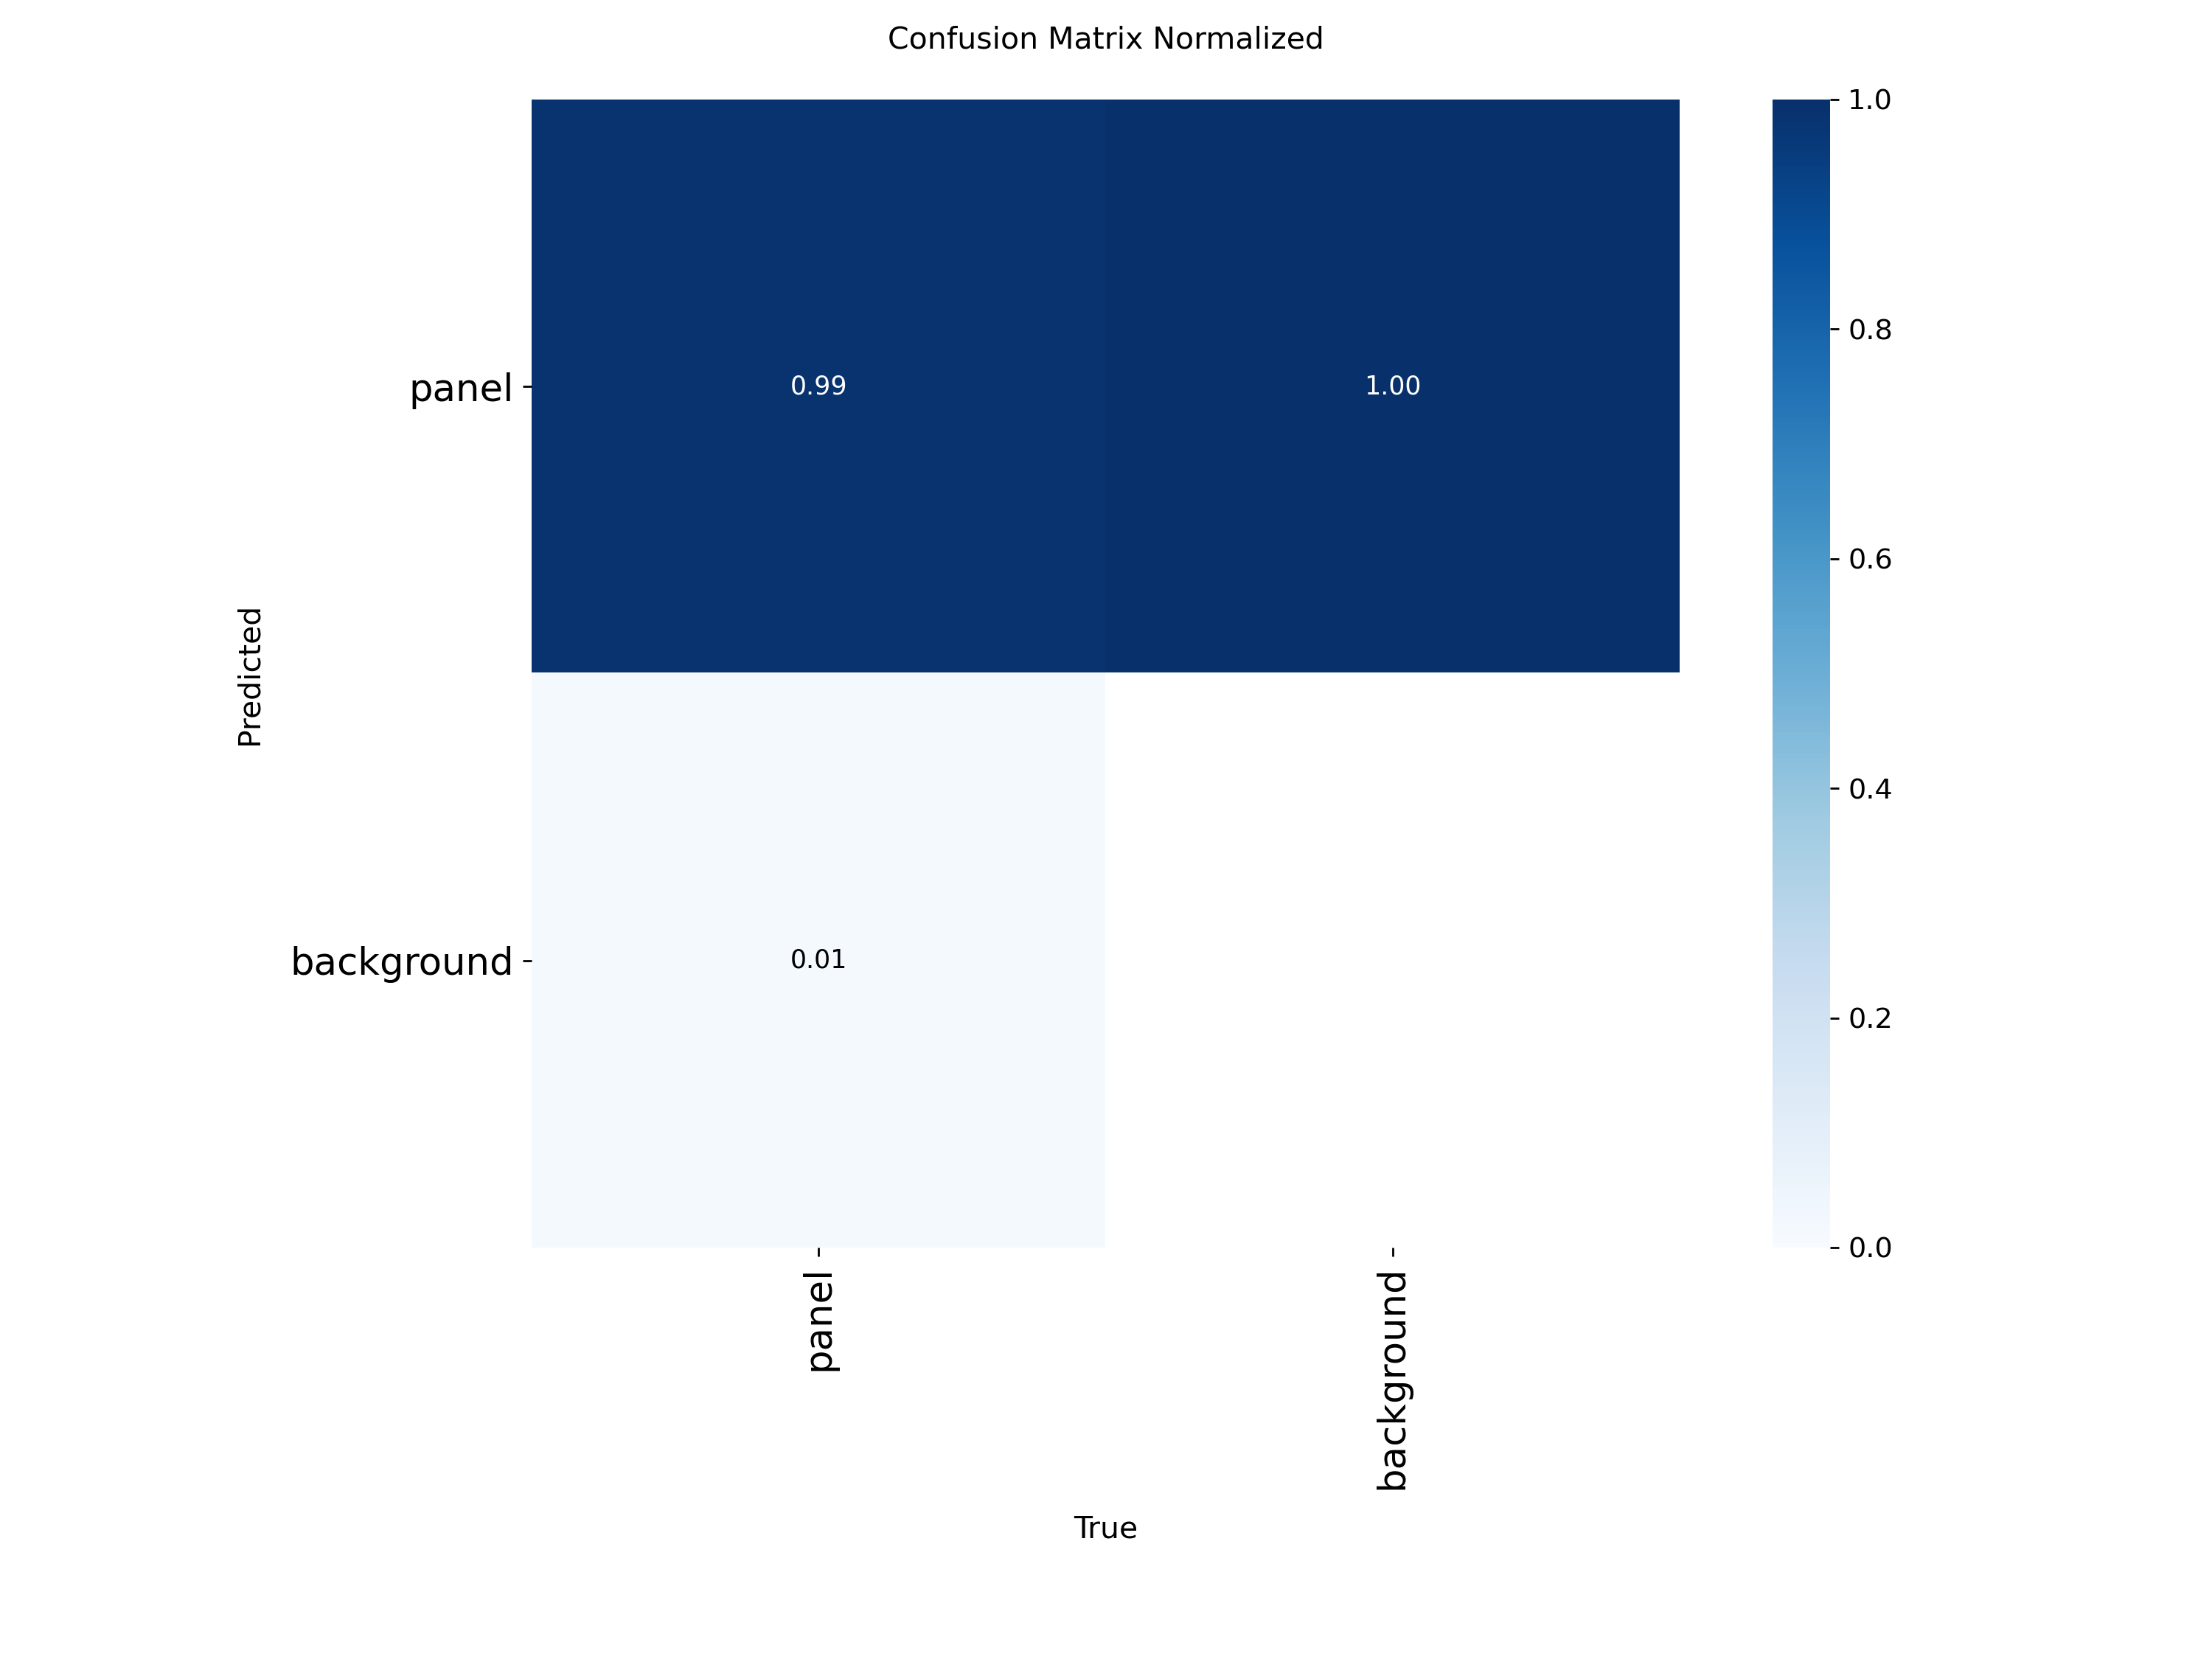

**Curva Precision-Recall (cajas)** — `BoxPR_curve.png`

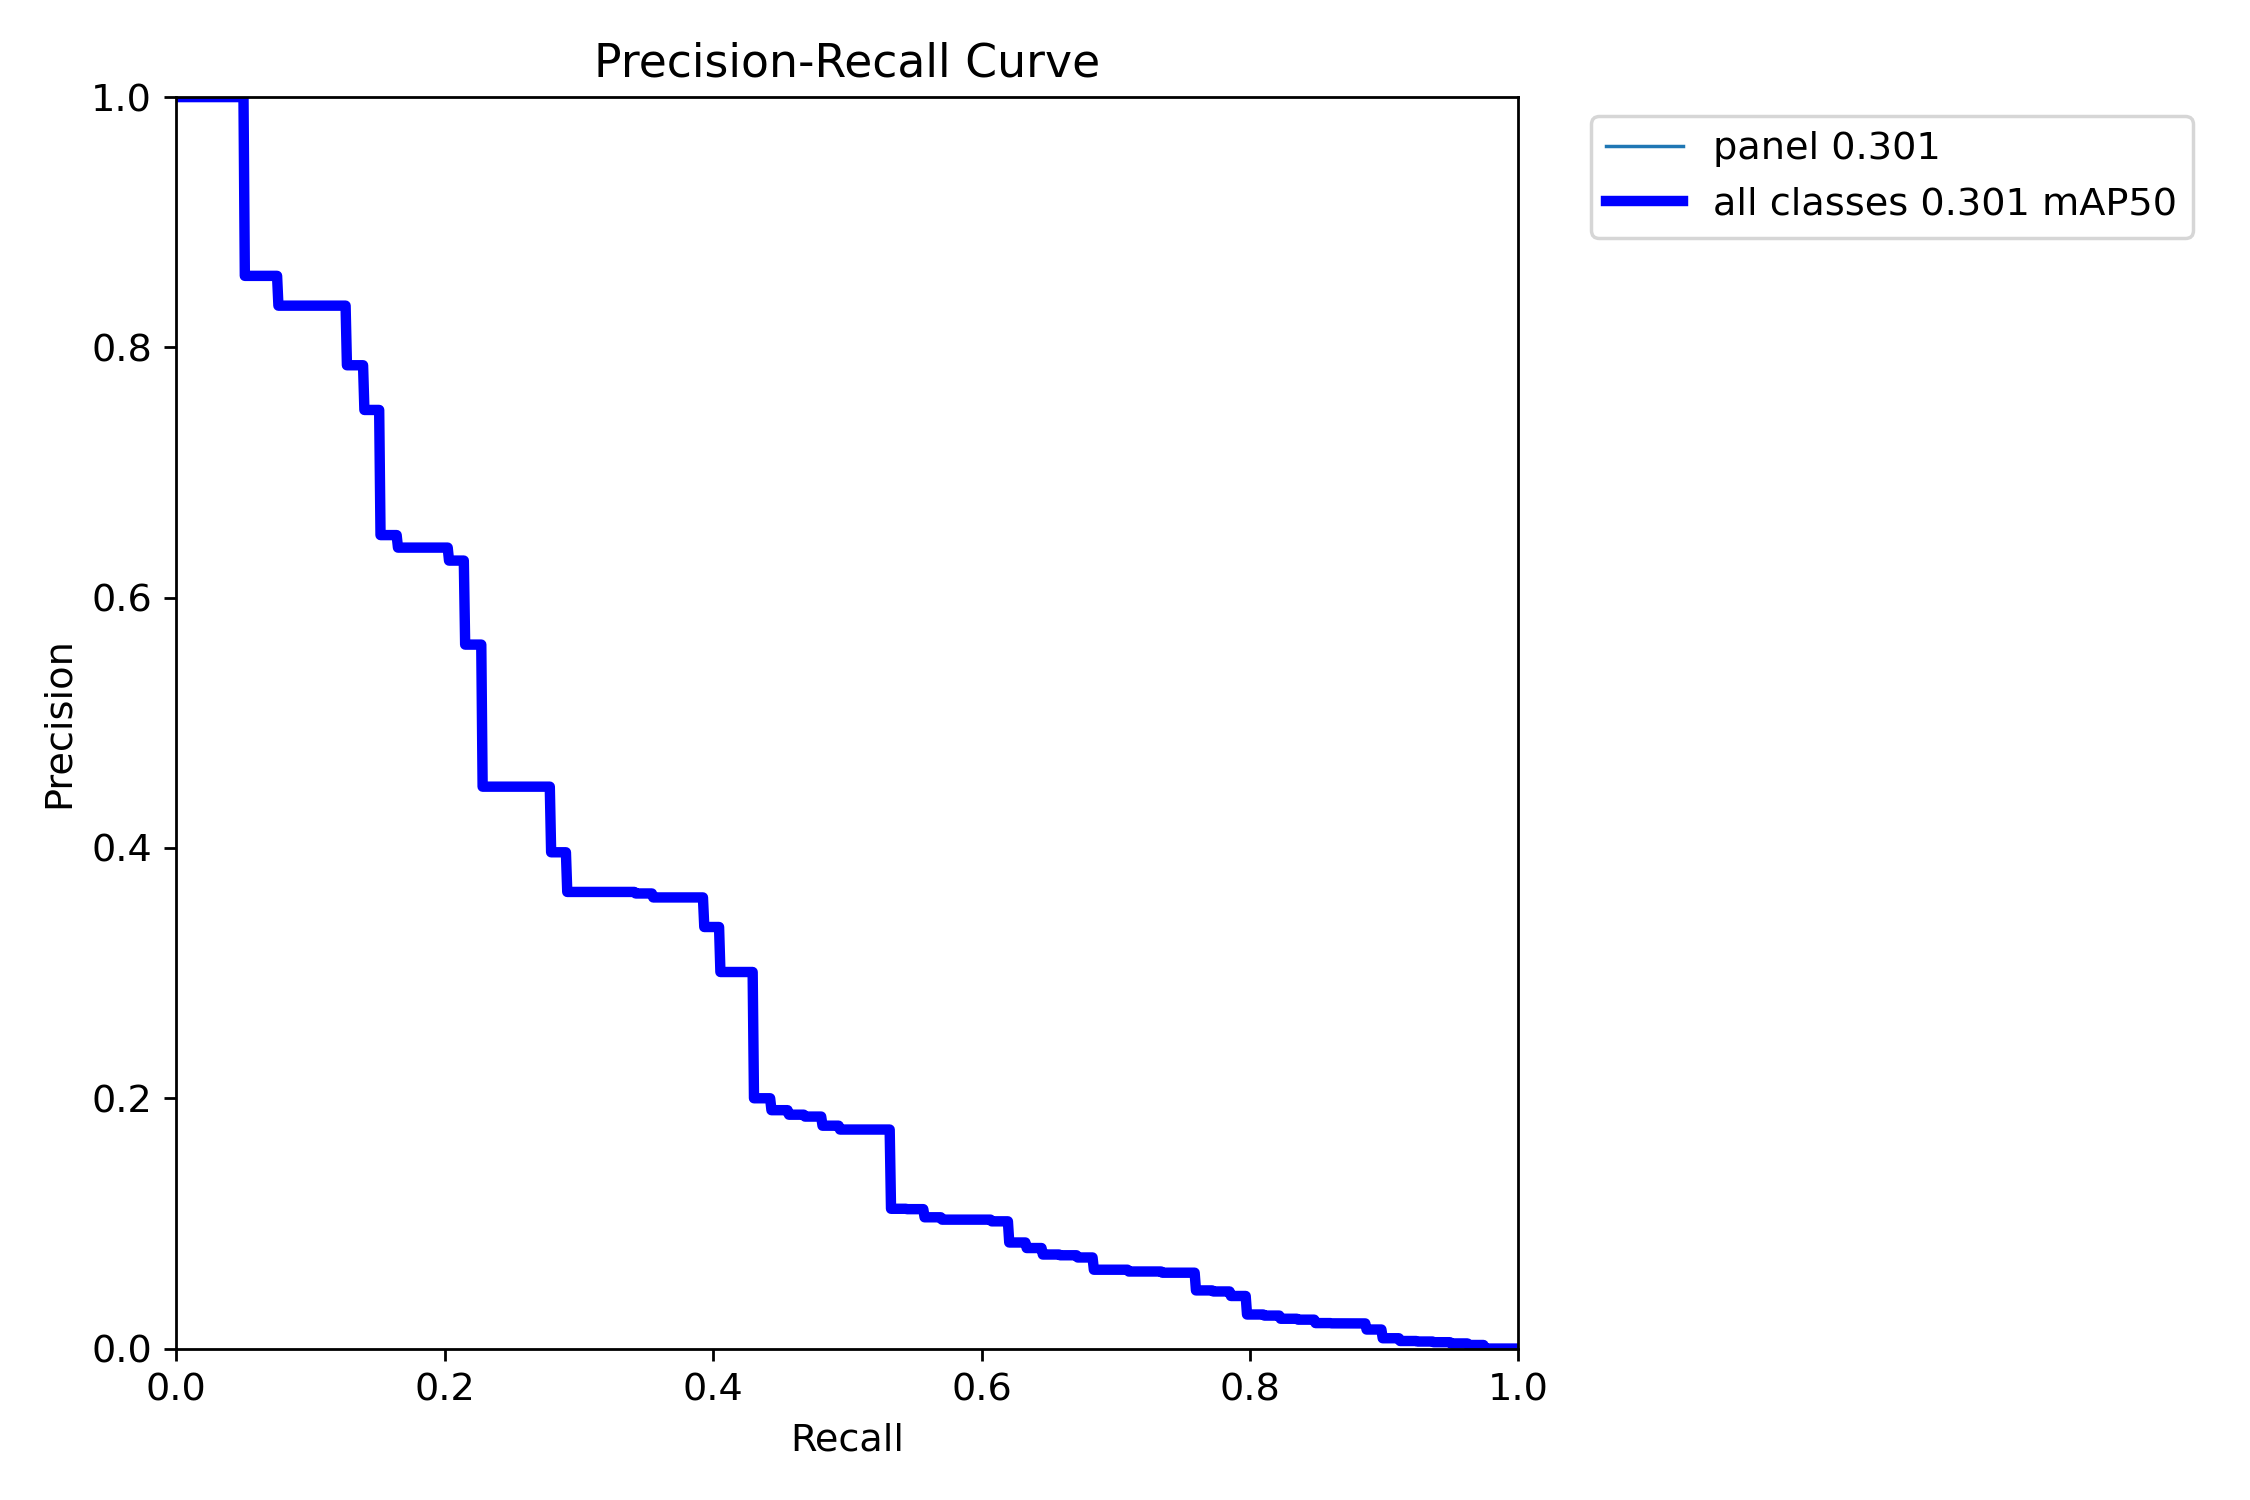

**Curva F1 (cajas)** — `BoxF1_curve.png`

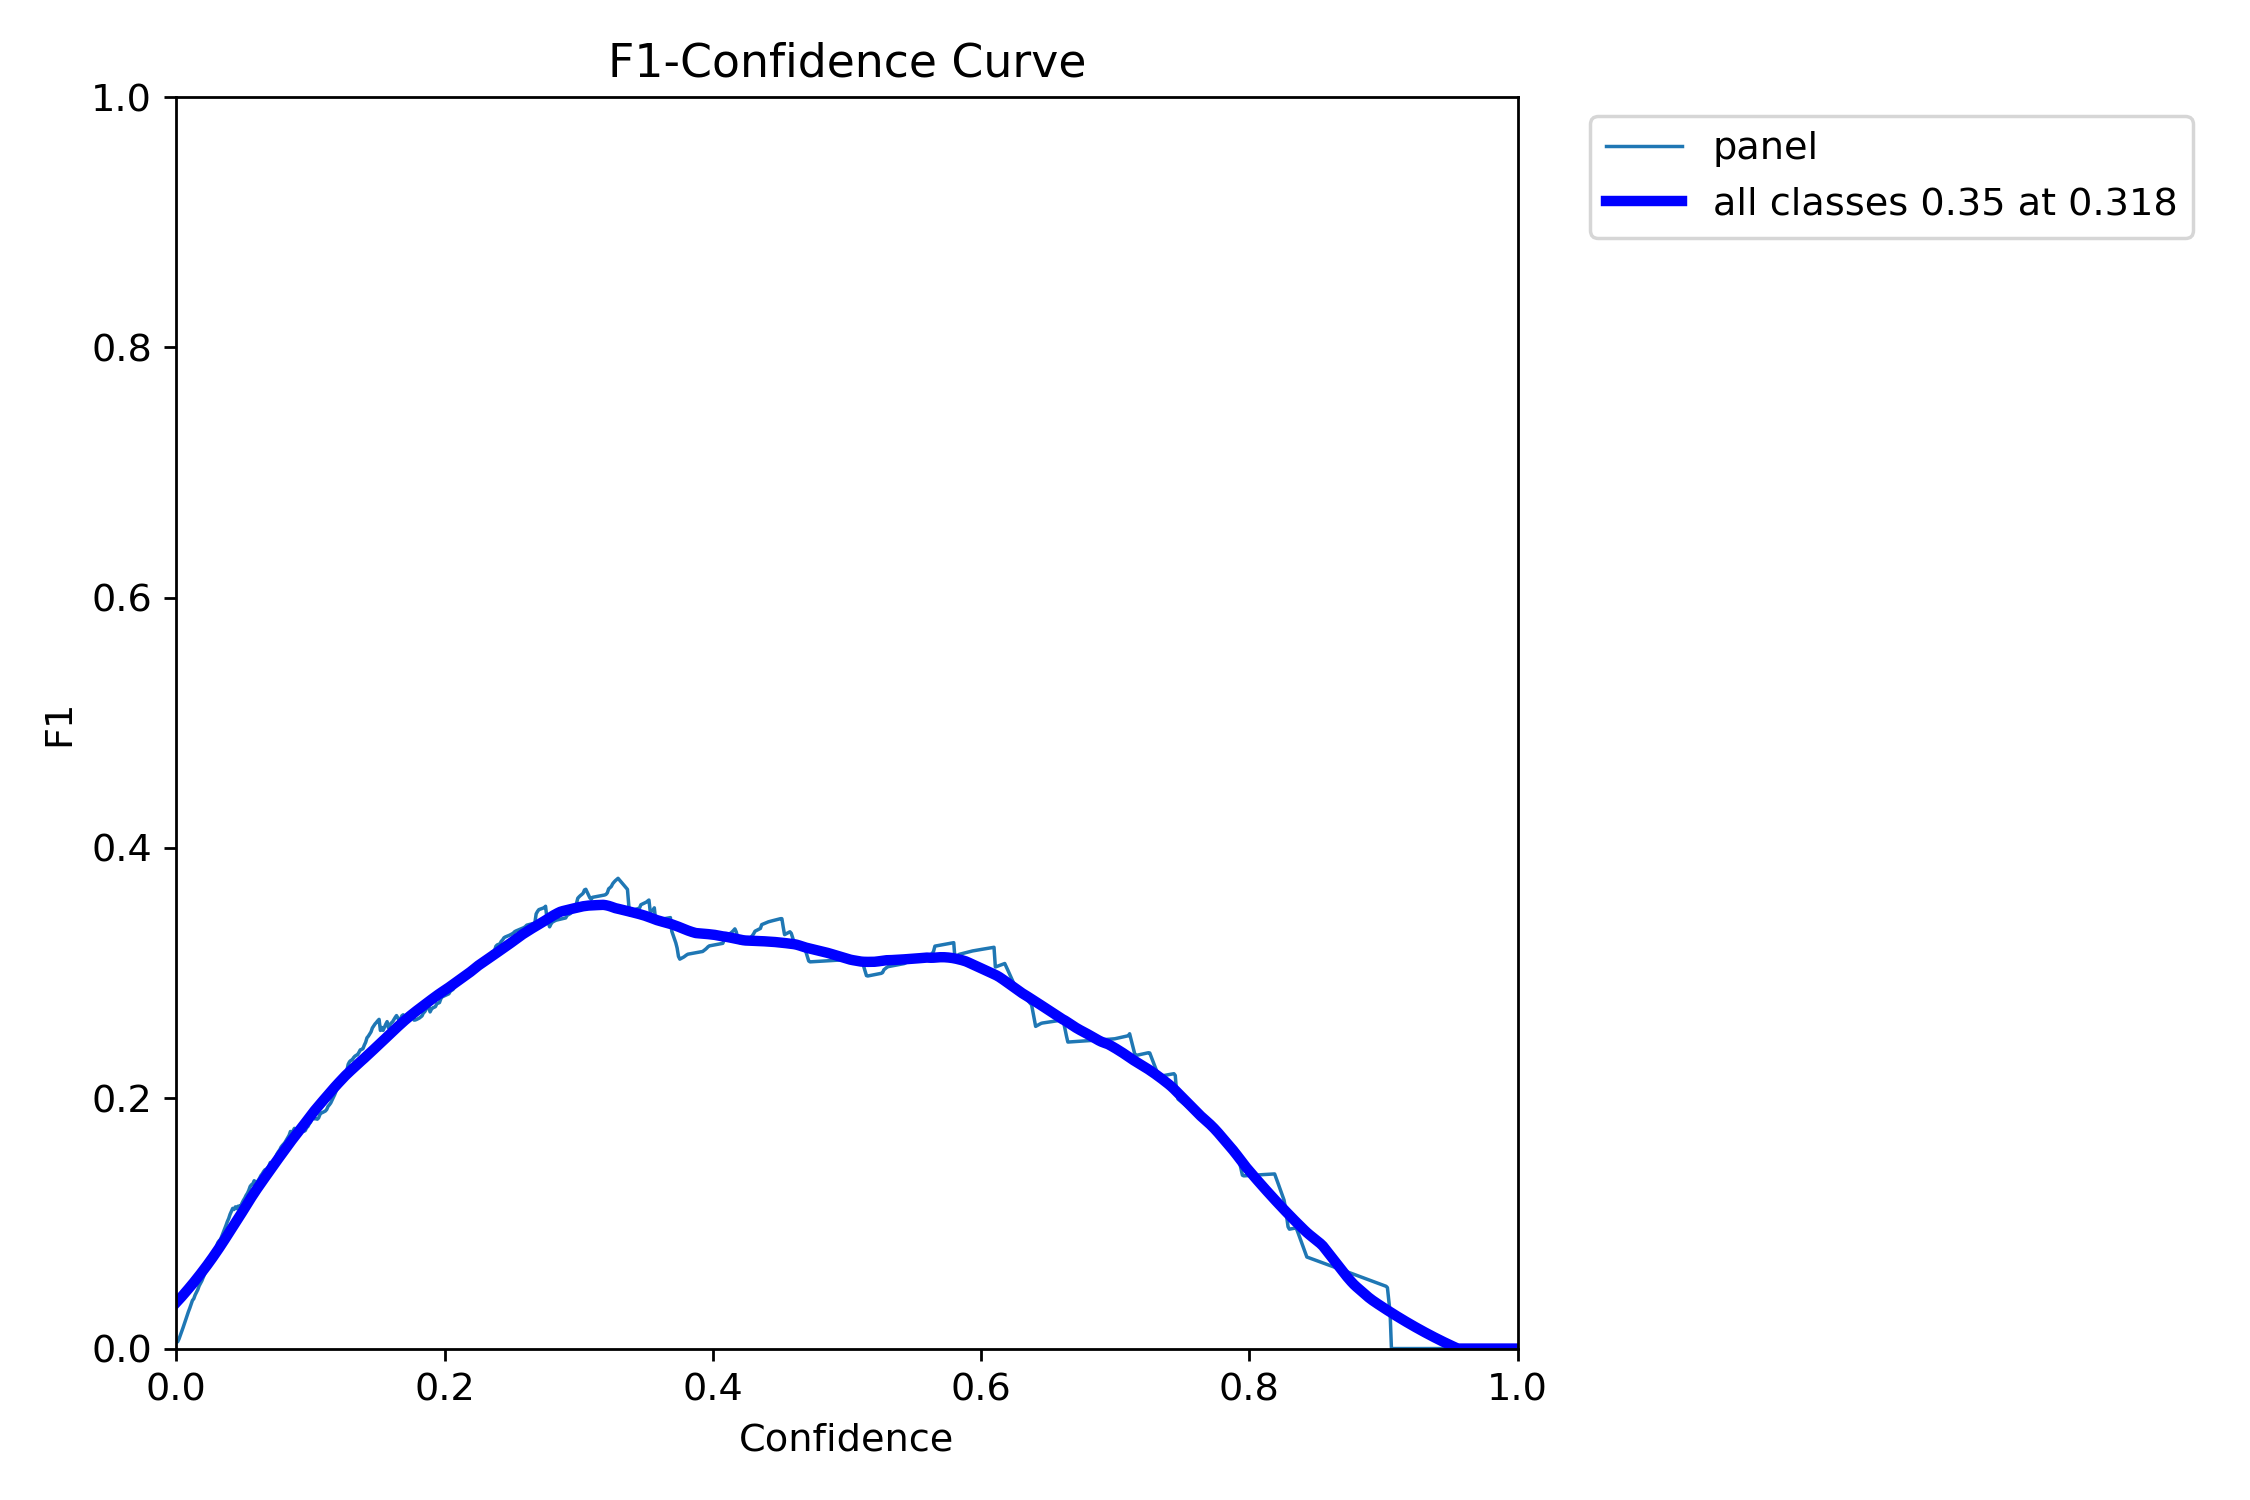

Experimentos recorridos: 3


In [25]:
def load_epoch_history(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    return df


def plot_training_curves(history: pd.DataFrame, title: str) -> None:
    epoch_col = col_first(history, "epoch")
    if epoch_col is None:
        print("results.csv sin columna epoch")
        return
    epochs = to_num(history[epoch_col])
    loss_groups = [
        ("box", col_first(history, "train/box_loss"), col_first(history, "val/box_loss")),
        ("cls", col_first(history, "train/cls_loss"), col_first(history, "val/cls_loss")),
        ("dfl", col_first(history, "train/dfl_loss"), col_first(history, "val/dfl_loss")),
    ]
    metric_specs = [
        ("mAP50", col_first(history, "metrics/mAP50(B)", "metrics/mAP50")),
        ("mAP50-95", col_first(history, "metrics/mAP50-95(B)", "metrics/mAP50-95")),
        ("Precision", col_first(history, "metrics/precision(B)", "metrics/precision")),
        ("Recall", col_first(history, "metrics/recall(B)", "metrics/recall")),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    axes = axes.ravel()
    for ax, (name, train_c, val_c) in zip(axes[:3], loss_groups):
        if train_c is None and val_c is None:
            ax.set_title(f"{name} loss (no disponible)")
            ax.axis("off")
            continue
        if train_c is not None:
            ax.plot(epochs, to_num(history[train_c]), label="train")
        if val_c is not None:
            ax.plot(epochs, to_num(history[val_c]), label="val")
        ax.set_title(f"{name} loss")
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

    ax = axes[3]
    plotted = False
    for label, col in metric_specs[:2]:
        if col is None:
            continue
        ax.plot(epochs, to_num(history[col]), label=label)
        plotted = True
    ax.set_title("mAP (deteccion)")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend(fontsize=8)
    else:
        ax.axis("off")

    ax = axes[4]
    plotted = False
    for label, col in metric_specs[2:]:
        if col is None:
            continue
        ax.plot(epochs, to_num(history[col]), label=label)
        plotted = True
    ax.set_title("Precision / Recall (cajas)")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend(fontsize=8)
    else:
        ax.axis("off")

    ax = axes[5]
    lr_cols = [c for c in history.columns if c.startswith("lr/")]
    if lr_cols:
        for c in lr_cols:
            ax.plot(epochs, to_num(history[c]), label=c)
        ax.set_title("Learning rate")
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    else:
        ax.axis("off")

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_image_confusion(summary_row: dict, title: str) -> None:
    cm = np.array(
        [
            [summary_row.get("tn", 0), summary_row.get("fp", 0)],
            [summary_row.get("fn", 0), summary_row.get("tp", 0)],
        ],
        dtype=float,
    )
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1], ["pred: no panel", "pred: panel"])
    ax.set_yticks([0, 1], ["GT: no panel", "GT: panel"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", color="black", fontsize=14)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()


def show_ultralytics_plots(exp_id: str) -> None:
    plot_dir = find_plot_dir(exp_id)
    if plot_dir is None:
        print(f"Sin plots Ultralytics para {exp_id}.")
        return
    shown = 0
    for filename, title in PLOT_CANDIDATES:
        path = plot_dir / filename
        if not path.is_file():
            continue
        display(Markdown(f"**{title}** — `{path.name}`"))
        display(Image(filename=str(path), width=520))
        shown += 1
    if shown == 0:
        print(f"{plot_dir} no tiene los PNG de PLOT_CANDIDATES.")


def show_experiment(architecture: str, strategy: str, fold: int) -> None:
    exp_id = experiment_id(architecture, strategy, fold)
    display(Markdown(f"---\n## {exp_id}\n{FOLD_LABEL[fold]} · {STRATEGY_LABEL[strategy]}"))

    row = None
    if not experiments.empty and "experiment_id" in experiments.columns:
        match = experiments[experiments["experiment_id"] == exp_id]
        if not match.empty:
            row = match.iloc[0]
            det_cols = [
                c for c in (
                    "status", "map50", "map50_95", "precision", "recall", "fitness",
                    "best_epoch", "epochs_ran", "train_time_sec", "frozen_indices", "warning", "error",
                )
                if c in experiments.columns
            ]
            display(Markdown("#### Deteccion (cajas)"))
            display(pd.DataFrame([row[det_cols]]))

    clf_match = image_clf[(image_clf["experiment_id"] == exp_id) & (image_clf["scope"] == "combined")] if not image_clf.empty else pd.DataFrame()
    if clf_match.empty or not bool(clf_match.iloc[0].get("available", False)):
        print("Sin predicciones para clasificacion imagen.")
    else:
        clf_row = clf_match.iloc[0].to_dict()
        display(Markdown(f"#### Clasificacion imagen (conf >= {IMAGE_CONF})"))
        show_cols = [
            c for c in (
                "n_images", "n_gt_positive", "n_gt_negative",
                "tp", "fp", "tn", "fn", "precision", "recall", "specificity", "f1", "accuracy",
            )
            if c in clf_match.columns
        ]
        display(pd.DataFrame([clf_match.iloc[0][show_cols]]))
        plot_image_confusion(clf_row, f"{exp_id} — imagen tiene/no tiene panel")
        if fold == 3:
            per_source = image_clf[(image_clf["experiment_id"] == exp_id) & (image_clf["scope"] == "source")]
            if not per_source.empty:
                display(Markdown("##### Por fuente (fold 3)"))
                display(per_source.reset_index(drop=True))

    if not fold_metrics.empty and "experiment_id" in fold_metrics.columns:
        fm = fold_metrics[fold_metrics["experiment_id"] == exp_id]
        if not fm.empty:
            display(Markdown("#### fold_metrics (deteccion / FP kingston2)"))
            display(fm.reset_index(drop=True))

    csv_path = find_results_csv(exp_id, row)
    if csv_path is None:
        print(f"No esta results.csv de {exp_id}")
    else:
        history = load_epoch_history(csv_path)
        best_epoch = None
        if row is not None and "best_epoch" in row.index and not pd.isna(row["best_epoch"]):
            best_epoch = int(row["best_epoch"])
        title = exp_id if best_epoch is None else f"{exp_id} (best epoch={best_epoch})"
        plot_training_curves(history, title)

    if SHOW_ULTRALYTICS_PLOTS:
        show_ultralytics_plots(exp_id)


n_shown = 0
for architecture in SELECTED_ARCHITECTURES:
    for strategy in SELECTED_STRATEGIES:
        for fold in SELECTED_FOLDS:
            show_experiment(architecture, strategy, fold)
            n_shown += 1
print(f"Experimentos recorridos: {n_shown}")


## 7. Vistas compactas — yolo26n backbone

Una fila con los 3 folds: confusión de detección, confusión imagen y box loss.


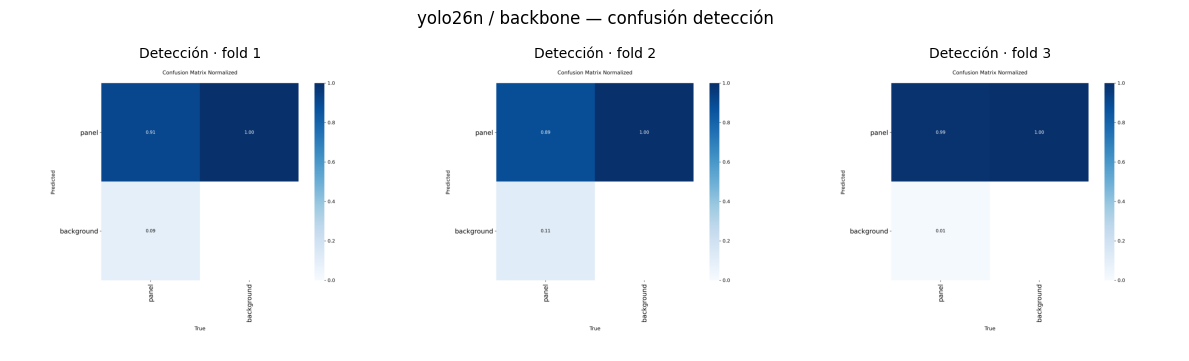

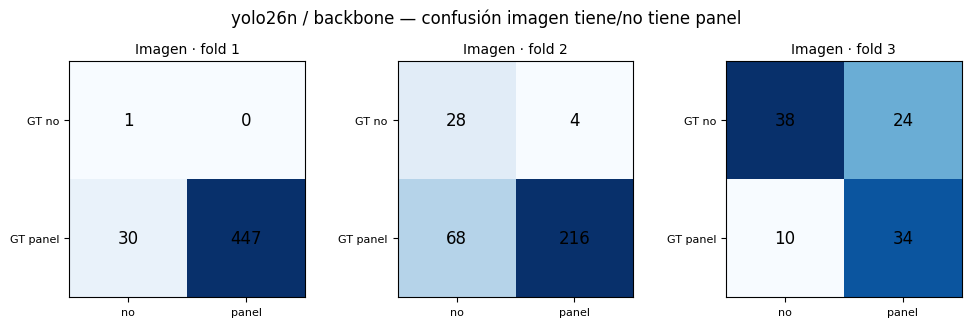

In [26]:
FOCUS_ARCH = "yolo26n"
FOCUS_STRAT = "backbone"


def confusion_path(exp_id: str):
    plot_dir = find_plot_dir(exp_id)
    if plot_dir is None:
        return None
    for name in ("confusion_matrix_normalized.png", "confusion_matrix.png"):
        path = plot_dir / name
        if path.is_file():
            return path
    return None


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for j, fold in enumerate(FOLDS):
    ax = axes[j]
    exp_id = experiment_id(FOCUS_ARCH, FOCUS_STRAT, fold)
    path = confusion_path(exp_id)
    ax.set_title(f"Detección · fold {fold}", fontsize=10)
    if path is None:
        ax.text(0.5, 0.5, "sin imagen", ha="center", va="center")
        ax.axis("off")
        continue
    ax.imshow(plt.imread(path))
    ax.axis("off")
fig.suptitle(f"{FOCUS_ARCH} / {FOCUS_STRAT} — confusión detección", fontsize=12)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for j, fold in enumerate(FOLDS):
    ax = axes[j]
    exp_id = experiment_id(FOCUS_ARCH, FOCUS_STRAT, fold)
    match = (
        image_clf[(image_clf["experiment_id"] == exp_id) & (image_clf["scope"] == "combined")]
        if not image_clf.empty else pd.DataFrame()
    )
    ax.set_title(f"Imagen · fold {fold}", fontsize=10)
    if match.empty or not bool(match.iloc[0].get("available", False)):
        ax.text(0.5, 0.5, "sin preds", ha="center", va="center")
        ax.axis("off")
        continue
    r = match.iloc[0]
    cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]], dtype=float)
    ax.imshow(cm, cmap="Blues")
    for ii in range(2):
        for jj in range(2):
            ax.text(jj, ii, int(cm[ii, jj]), ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1], ["no", "panel"], fontsize=8)
    ax.set_yticks([0, 1], ["GT no", "GT panel"], fontsize=8)
fig.suptitle(f"{FOCUS_ARCH} / {FOCUS_STRAT} — confusión imagen tiene/no tiene panel", fontsize=12)
plt.tight_layout()
plt.show()


## 8. Box loss train/val — yolo26n backbone


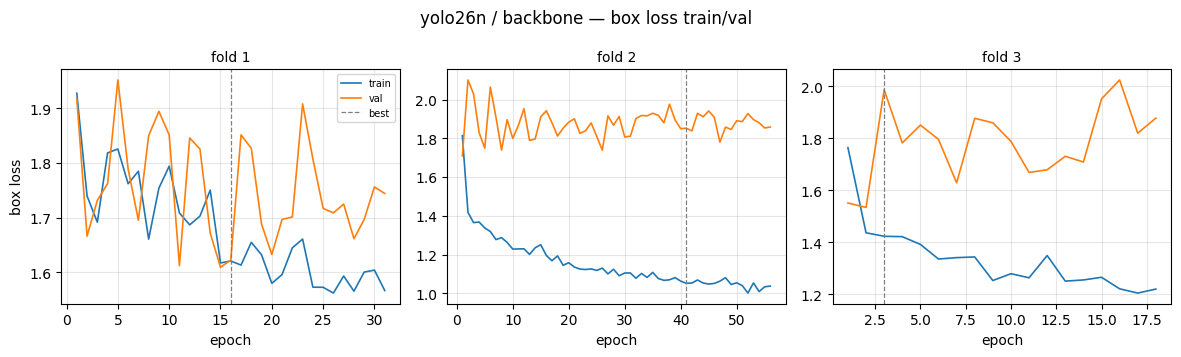

In [27]:
FOCUS_ARCH = "yolo26n"
FOCUS_STRAT = "backbone"

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for j, fold in enumerate(FOLDS):
    ax = axes[j]
    exp_id = experiment_id(FOCUS_ARCH, FOCUS_STRAT, fold)
    row = None
    if not experiments.empty and "experiment_id" in experiments.columns:
        match = experiments[experiments["experiment_id"] == exp_id]
        if not match.empty:
            row = match.iloc[0]
    csv_path = find_results_csv(exp_id, row)
    ax.set_title(f"fold {fold}", fontsize=10)
    if csv_path is None:
        ax.text(0.5, 0.5, "sin results.csv", ha="center", va="center", transform=ax.transAxes)
        continue
    history = load_epoch_history(csv_path)
    epoch_col = col_first(history, "epoch")
    train_c = col_first(history, "train/box_loss")
    val_c = col_first(history, "val/box_loss")
    if epoch_col is None or (train_c is None and val_c is None):
        ax.text(0.5, 0.5, "sin box_loss", ha="center", va="center", transform=ax.transAxes)
        continue
    epochs = to_num(history[epoch_col])
    if train_c is not None:
        ax.plot(epochs, to_num(history[train_c]), label="train", linewidth=1.2)
    if val_c is not None:
        ax.plot(epochs, to_num(history[val_c]), label="val", linewidth=1.2)
    if row is not None and "best_epoch" in row.index and not pd.isna(row["best_epoch"]):
        ax.axvline(int(row["best_epoch"]), color="gray", linestyle="--", linewidth=0.9, label="best")
    ax.grid(alpha=0.3)
    ax.set_xlabel("epoch")
    if j == 0:
        ax.set_ylabel("box loss")
        ax.legend(fontsize=7)
fig.suptitle(f"{FOCUS_ARCH} / {FOCUS_STRAT} — box loss train/val", fontsize=12)
plt.tight_layout()
plt.show()


## 9. Checklist de artefactos


In [28]:
rows = []
for architecture in ARCHITECTURES:
    for strategy in STRATEGIES:
        for fold in FOLDS:
            exp_id = experiment_id(architecture, strategy, fold)
            row = None
            if not experiments.empty and "experiment_id" in experiments.columns:
                match = experiments[experiments["experiment_id"] == exp_id]
                if not match.empty:
                    row = match.iloc[0]
            weights = RESULTS_DIR / "weights" / architecture / strategy / f"fold{fold}" / "best.pt"
            clf_ok = False
            if not image_clf.empty:
                m = image_clf[(image_clf["experiment_id"] == exp_id) & (image_clf["scope"] == "combined")]
                clf_ok = (not m.empty) and bool(m.iloc[0].get("available", False))
            rows.append(
                {
                    "experiment_id": exp_id,
                    "status": None if row is None else row.get("status", ""),
                    "experiments_csv": row is not None,
                    "results_csv": find_results_csv(exp_id, row) is not None,
                    "plots": find_plot_dir(exp_id) is not None,
                    "predictions": find_pred_labels_dir(exp_id, row) is not None,
                    "image_clf": clf_ok,
                    "best_pt": weights.is_file() and weights.stat().st_size > 0,
                    "map50_95": None if row is None else row.get("map50_95", np.nan),
                }
            )

checklist = pd.DataFrame(rows)
display(checklist)
print("con clasificacion imagen:", int(checklist["image_clf"].sum()), "/", len(checklist))


,experiment_id,status,experiments_csv,results_csv,plots,predictions,image_clf,best_pt,map50_95
0,yolov8n__full__fold1,completed,True,True,True,True,True,True,0.2748
1,yolov8n__full__fold2,completed,True,True,True,True,True,True,0.2584
2,yolov8n__full__fold3,completed,True,True,True,True,True,True,0.0477
3,yolov8n__backbone__fold1,completed,True,True,True,True,True,True,0.2625
4,yolov8n__backbone__fold2,completed,True,True,True,True,True,True,0.2559
5,yolov8n__backbone__fold3,completed,True,True,True,True,True,True,0.1019
6,yolov8n__partial__fold1,completed,True,True,True,True,True,True,0.3426
7,yolov8n__partial__fold2,completed,True,True,True,True,True,True,0.2552
8,yolov8n__partial__fold3,completed,True,True,True,True,True,True,0.0765
9,yolo11n__full__fold1,completed,True,True,True,True,True,True,0.2777


con clasificacion imagen: 27 / 27
